# ****Практическая работа. Геоанализ экологических факторов городской среды с применением методов пространственной кластеризации****

В этой работе вы не просто запускаете готовый алгоритм кластеризации. Главная задача — **самостоятельно построить логику исследования**: выбрать территорию, подобрать релевантные OSM-теги, превратить пространственные объекты в числовые признаки, осознанно выбрать алгоритм кластеризации и интерпретировать полученные группы территорий.

## ****Цель работы****

Освоить полный цикл пространственной кластеризации городской территории: от выбора экологически значимых признаков и OSM-тегов до построения H3-сетки, расчёта признаков, сравнения алгоритмов кластеризации и содержательной интерпретации кластеров.

---

## ****Что должно получиться в конце****

По итогам работы у вас должны быть:

1. Обоснованно выбранная территория исследования.
2. Таблица экологических признаков и OSM-тегов, которые вы используете для их загрузки.
3. H3-сетка, покрывающая выбранную территорию.
4. Набор числовых признаков для каждой H3-ячейки.
5. Сравнение нескольких алгоритмов кластеризации.
6. Карта кластеров.
7. Содержательная типология территорий: не просто «кластер 0 / кластер 1», а названия вроде «зелёные рекреационные зоны», «транспортно нагруженные территории», «промышленно-коммунальные зоны» и т.д.
8. Краткие рекомендации по улучшению экологической ситуации для каждого типа территории.

## ****Основной принцип работы****

Код в этом блокноте — это **заготовка**, а не готовый ответ.



Оценивается не то, насколько точно вы скопировали код (он уже скопирован по большей части), а то, насколько осмысленно вы приняли исследовательские решения:

- почему выбрали именно эту территорию;
- почему эти OSM-теги подходят для вашей задачи;
- какие признаки вы рассчитали и зачем;
- почему выбрали такое разрешение H3-сетки;
- почему использовали именно эти алгоритмы кластеризации;
- почему итоговые кластеры можно интерпретировать именно так.



Кластеризация — это метод без заранее известных правильных ответов. Поэтому качество результата определяется не только метриками, но и **смыслом полученных групп**.

## ****Перед началом****

Перед выполнением практической работы повторите материал занятия по кластерному анализу:



- зачем нужна нормализация признаков;
- чем отличаются K-means, агломеративная кластеризация, спектральная кластеризация, DBSCAN и HDBSCAN;
- как читать Silhouette Score, Calinski–Harabasz Index и Davies–Bouldin Index;
- почему один «лучший» алгоритм не всегда существует;
- как интерпретировать кластеры через средние значения признаков.



Ссылка на материалы занятий:


**Ознакомиться обязательно!**


- Методы машинного обучения без учителя: https://clck.ru/3Tn8A4


- Машинное обучение для пространственного анализа городской инфраструктуры: кластеризация и сравнительный анализ алгоритмов: https://clck.ru/3Tn8DM


---

# ****Часть 1. Постановка исследовательской задачи****

## ****1.1. Выбор территории исследования****

Выберите город или часть города для анализа. Это может быть:

- весь город;
- промышленный район;
- территория вдоль крупной автомагистрали;
- новая застройка;
- исторический центр;
- территория вокруг реки или водоёма;
- пригородная зона на границе городской и природной среды.

Важно, чтобы в выбранной территории потенциально были **разные типы экологической ситуации**. Если вся территория однородна, кластеризация может оказаться малоинформативной.

### ****Ответьте перед началом анализа****

Заполните этот блок текстом.

1. Какую территорию вы выбрали?
2. Почему эта территория интересна для экологического анализа?
3. Какие различия внутри территории вы ожидаете увидеть?
4. Какие экологические проблемы могут быть характерны для этой территории?
5. Какой масштаб анализа вам нужен: крупные зоны города, районы, кварталы?



**ВАШ ОТВЕТ:**

1. Для анализа выбрана территория города Железногорска Курской области, включая промышленную зону Михайловского горно-обогатительного комбината (МГОК), в состав которой входят карьер Михайловского рудника, отвалы вскрышных пород, хвостохранилище и обогатительная фабрика.
2. Город Железногорск расположен рядом с одним из крупнейших железорудных карьеров России. На относительно небольшой территории находятся жилые районы, промышленные объекты горнодобывающего комплекса и лесные массивы. Из-за такого близкого расположения разных объектов экологические условия на территории могут заметно различаться. Поэтому данная территория хорошо подходит для проведения кластерного анализа, который позволит выявить участки со схожими характеристиками и определить различия между ними.
3. На выбранной территории я ожидаю увидеть различия между промышленными, жилыми и природными зонами. В районе карьера и отвалов будет практически отсутствовать растительность, поскольку эти земли сильно изменены в результате добычи полезных ископаемых. В районе хвостохранилища и обогатительной фабрики будут преобладать техногенные объекты. В жилых кварталах ожидается сочетание застройки, дорог и зелёных насаждений. Лесные массивы и водные объекты, расположенные на периферии города, предположительно будут характеризоваться меньшим антропогенным воздействием. Таким образом, я ожидаю, что кластерный анализ позволит выделить несколько зон, различающихся по характеру земного покрова и степени антропогенного воздействия.
4. На выбранной территории могут наблюдаться экологические проблемы, связанные в первую очередь с работой горнодобывающего комплекса. Основными проблемами могут быть загрязнение воздуха пылью при проведении взрывных работ в карьере и её распространение с поверхности отвалов под воздействием ветра. Также существует риск загрязнения почвы и водных объектов вблизи хвостохранилища и промышленных сооружений. Дополнительное воздействие на окружающую среду оказывает железнодорожный и автомобильный транспорт, который создаёт шум и выбросы загрязняющих веществ. Кроме того, расширение промышленных территорий может приводить к сокращению лесных массивов. Близкое расположение жилых районов к промышленным объектам также может негативно влиять на условия проживания населения.
5. Нужен квартальный уровень: город небольшой (несколько километров в поперечнике), и при более крупных ячейках он попал бы всего в несколько десятков ячеек. Поэтому выбрано разрешение H3 = 9 (площадь ячейки около 0,1 км²). Оно позволяет отделить жилые кварталы от промзон и учесть влияние объектов комбината в буферах 800–1600 м.



---

In [1]:

# Установка библиотек для Google Colab.
# Если вы работаете локально и библиотеки уже установлены, эту ячейку можно пропустить.

!pip install geopandas osmnx leafmap h3 h3pandas shapely pyproj scikit-learn matplotlib seaborn mapclassify kneed hdbscan -q

In [2]:
# Импорт библиотек

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

from shapely.geometry import box, Polygon
from shapely.ops import unary_union

import osmnx as ox
import leafmap
import h3

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, SpectralClustering, DBSCAN
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except Exception:
    pass

try:
    from kneed import KneeLocator
except Exception:
    KneeLocator = None

## ****1.2. Выбор области интереса на карте****

Нарисуйте прямоугольник или полигон вокруг выбранной территории. После этого выполните следующую ячейку, чтобы получить `bbox`.

Если интерактивная карта не работает, можно вручную задать координаты в формате:



```python
bbox = [west, south, east, north]
```



где:

- `west` — западная долгота;
- `south` — южная широта;
- `east` — восточная долгота;
- `north` — северная широта.

In [3]:
# При надобности, измените центр карты под свой город.
# Пример ниже — Москва.
# Центр карты — г. Железногорск (Курская обл.)
CENTER_LAT = 52.338
CENTER_LON = 35.352
ZOOM = 12

m = leafmap.Map(center=[CENTER_LAT, CENTER_LON], zoom=ZOOM, draw_control=True)
m

Map(center=[52.338, 35.352], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom…

In [4]:
# Получаем bbox из нарисованной области.
# Если область не нарисована, используется примерный bbox для Москвы.

bbox = m.user_roi_bounds()

if bbox:
    print("Выбранный bbox:", bbox)
else:
    bbox = [35.32, 52.255, 35.585, 52.405]  # Замените на свою территорию
    print("ROI не выбран на карте. Используется bbox по умолчанию:", bbox)

west, south, east, north = bbox

ROI не выбран на карте. Используется bbox по умолчанию: [35.32, 52.255, 35.585, 52.405]


In [5]:
# Отображение bbox на карте для проверки границ территории
bbox_gdf = gpd.GeoDataFrame(
    {"name": ["Область исследования"]},
    geometry=[box(*bbox)],
    crs="EPSG:4326"
)

bbox_map = leafmap.Map(center=[(south + north) / 2, (west + east) / 2], zoom=12)
bbox_map.add_basemap("Esri.WorldImagery")  # спутниковый снимок: хорошо видны карьер, отвалы и хвостохранилище
bbox_map.add_gdf(
    bbox_gdf,
    layer_name="bbox",
    style={"color": "red", "weight": 3, "fillOpacity": 0.05}
)
bbox_map

Map(center=[52.33, 35.4525], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom…

## ****1.3. Формулировка экологических признаков****

Перед загрузкой данных нужно определить, **какие явления городской среды вы считаете экологически значимыми**.

Пример логики:

| Шаг | Вопрос | Пример |
|---|---|---|
| 1 | Какой экологический признак анализируем? | Транспортная нагрузка |
| 2 | Какие объекты в OSM отражают этот признак? | Магистрали, крупные дороги |
| 3 | Какие теги подходят? | `highway=motorway`, `highway=trunk`, `highway=primary` |
| 4 | Какой пространственный признак считаем? | Длина дорог в буфере 1600 м |
| 5 | Как влияет на экологию? | Негативно |

Ваша задача — выбрать **не менее 5 признаков**, при этом желательно, чтобы среди них были и позитивные, и негативные.

## ****Подсказки по выбору OSM-тегов****

OSM-тег обычно имеет вид `ключ=значение`, например:

- `leisure=park` — парк;
- `landuse=industrial` — промышленная зона;
- `highway=primary` — крупная дорога;
- `natural=water` — водный объект.



Полезные источники для проверки тегов:

- https://wiki.openstreetmap.org/wiki/RU:Объекты_карты
- https://wiki.openstreetmap.org/wiki/Map_features
- https://taginfo.openstreetmap.org/



Не выбирайте теги механически. Один и тот же экологический признак может быть представлен несколькими тегами. Например, зелёные зоны могут быть описаны через `leisure=park`, `landuse=forest`, `natural=wood`, `landuse=grass`, `leisure=garden`.

## ****Примеры признаков и тегов****

Эта таблица дана как пример. Вы можете использовать её, но должны адаптировать под свою территорию и задачу.



| Фактор | Возможные OSM-теги | Типичный расчётный признак | Влияние |
|---|---|---|---|
| Зелёные зоны | `leisure=park`, `leisure=garden`, `landuse=forest`, `natural=wood`, `landuse=grass` | площадь зелёных зон в буфере | Позитивное |
| Водные объекты | `natural=water`, `waterway=river`, `waterway=stream` | площадь или протяжённость воды | Позитивное |
| Промышленные территории | `landuse=industrial`, `man_made=works` | площадь промышленных зон, количество объектов | Негативное |
| Энергетическая инфраструктура | `power=plant`, `power=generator`, `power=substation` | количество объектов или площадь | Часто негативное / зависит от типа |
| Магистрали | `highway=motorway`, `highway=trunk`, `highway=primary`, `highway=secondary` | длина дорог в буфере | Негативное |
| Железные дороги | `railway=rail` | протяжённость железных дорог | Негативное или нейтральное по контексту |
| Мусорные и коммунальные объекты | `landuse=landfill`, `amenity=waste_disposal`, `amenity=recycling` | количество или площадь объектов | Обычно негативное, но требует пояснения |
| Рекреационная инфраструктура | `leisure=nature_reserve`, `tourism=picnic_site` | количество/площадь объектов | Позитивное |



**Важно:** некоторые теги могут давать мало объектов или не отражать нужный смысл в вашем городе. После загрузки обязательно проверьте, что именно найдено.

### ****Ваша таблица признаков****

Заполните таблицу. Не ограничивайтесь названиями тегов — объясните, почему они подходят.



| № | Фактор | Почему он важен для экологической оценки | OSM-теги | Ожидаемый тип геометрии | Какой признак будете считать | Влияние `+` / `−` | Обоснование выбора |
|---|---|---|---|---|---|---|---|
| 1 | Зелёные зоны и леса | Растительность задерживает пыль от карьера и отвалов, снижает шум и улучшает микроклимат | `landuse=forest`, `landuse=grass`, `landuse=meadow`, `natural=wood`, `natural=scrub`, `leisure=park`, `leisure=garden` | Полигоны | Доля площади зелёных зон в буфере 800 м | `+` | Вокруг Железногорска преобладают лесные массивы (`natural=wood`), а парков в OSM мало (24 объекта), поэтому одних городских тегов недостаточно. `natural=scrub` добавлен, потому что кустарником зарастают старые отвалы и окраины, это тоже растительный покров |
| 2 | Водные объекты | Водоёмы и реки улучшают микроклимат и повышают рекреационную ценность территории | `natural=water`, `waterway=river`, `waterway=stream`, `waterway=canal` | Полигоны (водоёмы), линии (реки, ручьи) | Площадь водоёмов в буфере 1600 м | `+` | Нужны два ключа: водоёмы размечены полигонами `natural=water`, реки и ручьи — линиями `waterway`. Хвостохранилище размечено другим тегом (`landuse=basin`), поэтому в этот слой не попадает |
| 3 | Горнодобывающие нарушенные земли | Карьер, отвалы и хвостохранилище — главный источник пыли, изменённого рельефа и загрязнения почв и вод | `landuse=quarry`, `landuse=landfill`, `landuse=basin` | Полигоны | Доля нарушенных земель в буфере 1600 м; расстояние до ближайшего объекта | `−` | Ключевой фактор именно для Железногорска. В OSM карьер «Михайловский рудник» и отвалы №1–7а размечены как `landuse=quarry`, «Отвал окисленных кварцитов» — как `landuse=landfill`, хвостохранилище МГОК — как `landuse=basin`. С тегами из примера (`landuse=industrial`) этот слой почти не загрузился бы |
| 4 | Промышленные территории | Обогатительная фабрика и промзоны дают выбросы, шум и грузовой транспорт | `landuse=industrial` | Полигоны | Площадь промзон в буфере 1600 м | `−` | В слой попадают горно-обогатительная фабрика МГОК, промплощадки и северная промзона города. Он отделён от слоя 3: переработка и производство — это не то же самое, что нарушенные земли. Тег `man_made=works` исключён: все 10 таких объектов в области лежат внутри полигонов `landuse=industrial`, и их площадь посчиталась бы дважды |
| 5 | Транспортная инфраструктура | Автомобильный и железнодорожный транспорт создаёт шум, выбросы и пыль при перевозке руды | `highway=motorway`, `highway=trunk`, `highway=primary`, `highway=secondary`, `railway=rail` | Линии | Протяжённость дорог и железных дорог в буфере 1600 м | `−` | Руду и концентрат вывозят по железной дороге: внутри области 394 участка путей, большая часть — в районе карьера. Поэтому железная дорога здесь важнее, чем для обычного города. Мелкие улицы не включены: они есть почти везде и не различают территорию |

---

## ****1.4. Перевод выбранных признаков в словарь для загрузки OSM****

Ниже дана заготовка. Измените её так, чтобы она соответствовала вашей таблице признаков.

Обратите внимание:

- название слоя должно быть понятным: `green`, `industry`, `major_roads`, `water`;
- в `tags` указываются OSM-теги;
- в `influence` указывается направление влияния: `+` для позитивного, `-` для негативного, `mixed` если влияние зависит от контекста;
- в `reason` напишите короткое объяснение, зачем этот слой нужен.

In [6]:
# Адаптируйте этот словарь под свою территорию и исследовательскую задачу.
# Минимум: 5 признаков. Желательно: 6-8 признаков.

FACTOR_CATALOG = {
    "green": {
        "name": "Зелёные зоны и леса",
        "tags": {
            "landuse": ["forest", "grass", "meadow"],
            "natural": ["wood", "scrub"],
            "leisure": ["park", "garden"]
        },
        "influence": "+",
        "reason": "Растительность задерживает пыль от карьера и отвалов, снижает шум и улучшает микроклимат."
    },
    "water": {
        "name": "Водные объекты",
        "tags": {
            "natural": ["water"],
            "waterway": ["river", "stream", "canal"]
        },
        "influence": "+",
        "reason": "Водоёмы и реки улучшают микроклимат и повышают рекреационную ценность территории."
    },
    "mining": {
        "name": "Горнодобывающие нарушенные земли",
        "tags": {
            "landuse": ["quarry", "landfill", "basin"]
        },
        "influence": "-",
        "reason": "Карьер, отвалы и хвостохранилище МГОК — главный источник пыли и загрязнения почв и вод."
    },
    "industry": {
        "name": "Промышленные территории",
        "tags": {
            "landuse": ["industrial"]
        },
        "influence": "-",
        "reason": "Обогатительная фабрика и промзоны создают выбросы, шум и грузовой транспорт."
    },
    "transport": {
        "name": "Автомобильные и железные дороги",
        "tags": {
            "highway": ["motorway", "trunk", "primary", "secondary"],
            "railway": ["rail"]
        },
        "influence": "-",
        "reason": "Транспорт, в том числе вывоз руды по железной дороге, создаёт шум, выбросы и пыль."
    }
}

# Проверьте, что в словаре есть минимум 5 признаков.
print("Количество выбранных признаков:", len(FACTOR_CATALOG))
for key, value in FACTOR_CATALOG.items():
    print(f"{key}: {value['name']} -> {value['tags']}")

Количество выбранных признаков: 5
green: Зелёные зоны и леса -> {'landuse': ['forest', 'grass', 'meadow'], 'natural': ['wood', 'scrub'], 'leisure': ['park', 'garden']}
water: Водные объекты -> {'natural': ['water'], 'waterway': ['river', 'stream', 'canal']}
mining: Горнодобывающие нарушенные земли -> {'landuse': ['quarry', 'landfill', 'basin']}
industry: Промышленные территории -> {'landuse': ['industrial']}
transport: Автомобильные и железные дороги -> {'highway': ['motorway', 'trunk', 'primary', 'secondary'], 'railway': ['rail']}


### ****Проверка смысла выбранных тегов****

Перед загрузкой данных ответьте:

1. Какие теги вы оставили из примера?
2. Какие теги добавили самостоятельно?
3. Какие теги исключили и почему?
4. Есть ли среди ваших признаков такие, где влияние неоднозначно?
5. Что вы будете делать, если по выбранному тегу в OSM окажется мало объектов?



**ВАШ ОТВЕТ:**

1. **Какие теги оставлены из примера.**
   - Зелёные зоны: `leisure=park`, `leisure=garden`, `landuse=forest`, `landuse=grass`, `landuse=meadow`, `natural=wood`.
   - Водные объекты: `natural=water`, `waterway=river`, `waterway=stream`, `waterway=canal`.
   - Промышленность: `landuse=industrial`.
   - Крупные дороги: `highway=motorway`, `highway=trunk`, `highway=primary`, `highway=secondary`.
   - `landuse=landfill` тоже оставлен, но перенесён из слоя «мусорные объекты» в слой «горнодобывающие нарушенные земли»: в Железногорске под этим тегом размечен отвал окисленных кварцитов МГОК, а не свалка бытовых отходов.

2. **Какие теги добавлены самостоятельно.**
   - `landuse=quarry` — главный тег для территории: так в OSM размечены карьер «Михайловский рудник» и отвалы вскрышных пород.
   - `landuse=basin` — под этим тегом размечено хвостохранилище МГОК, крупнейший техногенный объект на северо-востоке территории, а также технические бассейны-отстойники.
   - `natural=scrub` — кустарниковая растительность. Вокруг города и на старых отвалах много зарастающих участков, и без этого тега часть растительного покрова была бы потеряна.
   - `railway=rail` — по железной дороге вывозят руду и концентрат, значительная часть путей проходит в районе карьера. Для горнодобывающего города это важный источник шума и пыли.

3. **Какие теги исключены и почему.**
   - `man_made=works` — объекты с этим тегом лежат внутри полигонов `landuse=industrial`. Метрика площади суммирует пересечения, поэтому эти участки посчитались бы дважды.
   - `amenity=waste_disposal` и `amenity=recycling` — это в основном точечные объекты (контейнеры, пункты приёма), их вклад несопоставим с карьером и отвалами. К тому же пункты приёма вторсырья скорее положительный, чем отрицательный признак. Поэтому отдельный слой «мусорные объекты» убран, а реальные источники загрязнения (отвалы, хвостохранилище) вошли в слой `mining`.
   - Мелкие дороги (`highway=tertiary`, `residential` и ниже) не включены: они есть почти в каждом квартале и не различают территорию по транспортной нагрузке.

4. **Есть ли признаки с неоднозначным влиянием.** Да, несколько:
   - `natural=scrub`, `landuse=grass` и `landuse=meadow` на отвалах — часть зелёных объектов пересекается с нарушенными землями. Это самозарастание отвалов: растительность закрепляет грунт и снижает пыление, но сама территория остаётся техногенной. Признак учитывается как позитивный, но при интерпретации кластеров это нужно иметь в виду.
   - `landuse=basin` — кроме хвостохранилища под этим тегом есть безымянные бассейны. Скорее всего, это технические отстойники (негативный фактор), но часть может оказаться обычными прудами.
   - `natural=water` — часть водоёмов рядом с обогатительной фабрикой может быть технической (пруды-накопители), а не природной. Поэтому вблизи промплощадок «вода» не всегда означает экологическое благополучие.
   - `railway=rail` — значительная часть путей проходит внутри карьера, поэтому признак может частично дублировать слой `mining`. Это стоит проверить по корреляциям в части 5.

5. **Что делать, если по тегу окажется мало объектов.**
   - Сначала проверить количество объектов и их расположение на карте (часть 2.2) и сравнить со спутниковым снимком. Ноль в признаке не всегда означает, что объекта нет в реальности: возможно, он просто не размечен в OSM.
   - Расширить набор тегов синонимами по OSM Wiki и taginfo. Например, парков в городе немного, поэтому зелёные зоны дополнены лесами и кустарником (`natural=wood`, `natural=scrub`), иначе признак во многих ячейках был бы нулевым.
   - Изменить метрику: для редких объектов вместо площади или доли в буфере использовать расстояние до ближайшего объекта (`distance`) или количество (`count`), либо увеличить радиус буфера.
   - Если слой всё равно остаётся почти пустым, объединить его с близким по смыслу слоем или исключить из кластеризации и указать это в ограничениях исследования.

---

# ****Часть 2. Загрузка и проверка данных из OpenStreetMap****

## ****2.1. Функция загрузки данных****

Функция ниже загружает каждый слой из `FACTOR_CATALOG`. Она также создаёт пустой `GeoDataFrame`, если по выбранным тегам ничего не найдено. Это важно: пустой слой — не ошибка кода, а сигнал, что нужно проверить теги или выбранную территорию.

In [7]:
def features_from_bbox_compat(bbox, tags):  # Функция-обёртка для совместимости с разными версиями OSMnx
    """
    Совместимый вызов OSMnx для разных версий библиотеки.
    bbox задаётся как [west, south, east, north].
    """
    west, south, east, north = bbox  # Распаковка координат bbox
    try:  # Попытка вызова для OSMnx >= 2.0 (bbox как кортеж)
        return ox.features_from_bbox((west, south, east, north), tags=tags)  # Передаём bbox одним аргументом
    except TypeError:  # Если формат не подошёл — пробуем старый API
        try:  # Попытка вызова для OSMnx < 2.0 (отдельные координаты)
            return ox.features_from_bbox(north, south, east, west, tags)  # Передаём координаты по отдельности
        except TypeError:  # Если и это не сработало — именованный аргумент
            return ox.features_from_bbox(bbox=(west, south, east, north), tags=tags)  # Явно указываем bbox=


def load_osm_layers(bbox, factor_catalog, crs_out="EPSG:3857"):  # Загрузка нескольких слоёв OSM по каталогу
    """
    Загружает слои OSM по словарю признак -> теги.
    Возвращает словарь GeoDataFrame-ов в метрической проекции.
    """
    data = {}  # Словарь для хранения загруженных слоёв

    for layer_key, params in factor_catalog.items():  # Итерация по всем слоям в каталоге
        print(f"\nЗагрузка слоя: {layer_key} — {params['name']}")  # Лог: имя текущего слоя
        print("Теги:", params["tags"])  # Лог: теги для запроса

        try:  # Блок обработки ошибок загрузки
            gdf = features_from_bbox_compat(bbox, params["tags"])  # Загрузка объектов из OSM
            if gdf is None or gdf.empty:  # Проверка на пустой результат
                print("  Нет объектов по выбранным тегам.")  # Лог: данных нет
                data[layer_key] = gpd.GeoDataFrame(columns=["geometry"], geometry="geometry", crs=crs_out)  # Пустой GeoDataFrame
                continue  # Переход к следующему слою

            gdf = gdf.reset_index()  # Сброс индекса (OSMnx возвращает MultiIndex)
            gdf = gdf[gdf.geometry.notna()].copy()  # Удаление строк без геометрии
            gdf = gdf.set_geometry("geometry")  # Явное указание столбца геометрии

            if gdf.crs is None:  # Проверка наличия CRS
                gdf = gdf.set_crs("EPSG:4326")  # Установка WGS84 по умолчанию (стандарт OSM)

            gdf = gdf.to_crs(crs_out)  # Перепроецирование в целевую метрическую CRS
            gdf = gdf[gdf.geometry.is_valid]  # Фильтрация невалидных геометрий
            data[layer_key] = gdf  # Сохранение слоя в словарь
            print(f"  Загружено объектов: {len(gdf)}")  # Лог: количество загруженных объектов

        except Exception as e:  # Обработка любых исключений
            print(f"  Ошибка загрузки слоя {layer_key}: {e}")  # Лог: сообщение об ошибке
            data[layer_key] = gpd.GeoDataFrame(columns=["geometry"], geometry="geometry", crs=crs_out)  # Пустой GeoDataFrame при ошибке

    return data  # Возврат словаря со всеми слоями

In [8]:
# Загрузка выбранных признаков

crs_proj = "EPSG:32636"
data = load_osm_layers(bbox, FACTOR_CATALOG, crs_out=crs_proj)


Загрузка слоя: green — Зелёные зоны и леса
Теги: {'landuse': ['forest', 'grass', 'meadow'], 'natural': ['wood', 'scrub'], 'leisure': ['park', 'garden']}
  Загружено объектов: 1614

Загрузка слоя: water — Водные объекты
Теги: {'natural': ['water'], 'waterway': ['river', 'stream', 'canal']}
  Загружено объектов: 237

Загрузка слоя: mining — Горнодобывающие нарушенные земли
Теги: {'landuse': ['quarry', 'landfill', 'basin']}
  Ошибка загрузки слоя mining: 'overpass-api.de' responded: 502 Bad Gateway # 502 Gateway Timeout

This Overpass API server is currently at capacity. All query workers are busy
and the request queue is full.

## What to do

Retry your request using exponential backoff: wait a short interval, then retry.
If the request fails again, double the wait time and retry again.

## For heavy or automated use

This public endpoint is intended for browser-based and human-operated tools.
For automated or high-volume use, run a local Overpass API instance:

https://github.com/b1tw1

In [24]:
# Загрузка выбранных признаков.
# 1) Если слои уже сохранены на Google Диске — берём их оттуда, без запросов к OSM.
# 2) Иначе загружаем из OSM через зеркала Overpass с повторными попытками
#    и сохраняем на Диск, чтобы при перезапуске среды не загружать заново.
import os
import time

crs_proj = "EPSG:32636"  # UTM зона 36N — метрическая проекция без искажений на широте Железногорска

USE_DRIVE = True  # Сохранять/загружать слои через Google Диск
SAVE_DIR = "/content/drive/MyDrive/pr4_osm_layers"  # Папка для слоёв на Диске
SAVE_COLS = ["name", "landuse", "natural", "leisure", "man_made",
             "waterway", "highway", "railway", "usage"]  # Атрибуты, которые сохраняем вместе с геометрией

if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")  # Подключение Google Диска (при первом запуске попросит разрешение)
        os.makedirs(SAVE_DIR, exist_ok=True)
    except Exception as e:
        print("Google Диск недоступен, слои будут загружены из OSM:", e)
        USE_DRIVE = False

data = {}  # Словарь для хранения загруженных слоёв

# Шаг 1. Загрузка сохранённых слоёв с Диска
if USE_DRIVE:
    for k in FACTOR_CATALOG:
        path = f"{SAVE_DIR}/{k}.gpkg"
        if os.path.exists(path):
            data[k] = gpd.read_file(path).to_crs(crs_proj)
            print(f"Слой {k} загружен с Диска: {len(data[k])} объектов")

# Шаг 2. Загрузка недостающих слоёв из OSM
OVERPASS_URLS = [  # Список серверов Overpass: зеркало и основной сервер
    "https://maps.mail.ru/osm/tools/overpass/api",
    "https://overpass-api.de/api",
]
ox.settings.requests_timeout = 180  # Таймаут одного запроса, с
ox.settings.use_cache = True  # Кэширование успешных ответов
ox.settings.overpass_rate_limit = False  # Не ждать «свободного слота» сервера — иначе запрос может зависнуть надолго

for attempt in range(1, 6):  # До 5 попыток
    missing = [k for k in FACTOR_CATALOG if k not in data or data[k].empty]  # Слои, которые ещё не загружены
    if not missing:  # Все слои загружены
        break
    ox.settings.overpass_url = OVERPASS_URLS[(attempt - 1) % len(OVERPASS_URLS)]  # Чередование серверов
    print(f"\n=== Попытка {attempt}: сервер {ox.settings.overpass_url}, слои: {missing}")
    loaded = load_osm_layers(bbox, {k: FACTOR_CATALOG[k] for k in missing}, crs_out=crs_proj)  # Загрузка недостающих слоёв

    for k, gdf in loaded.items():
        data[k] = gdf
        if USE_DRIVE and not gdf.empty:  # Сохранение успешно загруженного слоя на Диск
            cols = [c for c in SAVE_COLS if c in gdf.columns] + ["geometry"]
            gdf[cols].to_file(f"{SAVE_DIR}/{k}.gpkg", driver="GPKG")
            print(f"  Слой {k} сохранён на Диск")

    if any(data[k].empty for k in missing):  # Если что-то снова не загрузилось — пауза перед следующей попыткой
        time.sleep(15 * attempt)

# Восстанавливаем порядок слоёв как в FACTOR_CATALOG
data = {k: data[k] for k in FACTOR_CATALOG if k in data}

print("\nИтог загрузки:")
for k, v in data.items():
    print(f"  {k}: {len(v)} объектов")

Mounted at /content/drive

=== Попытка 1: сервер https://maps.mail.ru/osm/tools/overpass/api, слои: ['green', 'water', 'mining', 'industry', 'transport']

Загрузка слоя: green — Зелёные зоны и леса
Теги: {'landuse': ['forest', 'grass', 'meadow'], 'natural': ['wood', 'scrub'], 'leisure': ['park', 'garden']}
  Загружено объектов: 1614

Загрузка слоя: water — Водные объекты
Теги: {'natural': ['water'], 'waterway': ['river', 'stream', 'canal']}
  Загружено объектов: 237

Загрузка слоя: mining — Горнодобывающие нарушенные земли
Теги: {'landuse': ['quarry', 'landfill', 'basin']}
  Загружено объектов: 27

Загрузка слоя: industry — Промышленные территории
Теги: {'landuse': ['industrial']}
  Загружено объектов: 120

Загрузка слоя: transport — Автомобильные и железные дороги
Теги: {'highway': ['motorway', 'trunk', 'primary', 'secondary'], 'railway': ['rail']}
  Загружено объектов: 461
  Слой green сохранён на Диск
  Слой water сохранён на Диск
  Слой mining сохранён на Диск
  Слой industry сохра

## ****2.2. Первичная проверка загруженных слоёв****

После загрузки важно проверить не только количество объектов, но и типы геометрии.

Почему это важно:

- площадь можно корректно считать только для полигонов;
- длину — для линий;
- количество — почти для любых объектов;
- расстояние до ближайшего объекта можно считать для любых геометрий, но смысл результата зависит от признака.

In [25]:
def layer_summary(data, factor_catalog):  # Функция для создания сводной таблицы по загруженным слоям
    rows = []  # Список для накопления строк будущего DataFrame
    for key, gdf in data.items():  # Итерация по всем загруженным слоям
        geom_types = [] if gdf.empty else sorted(gdf.geometry.geom_type.dropna().unique().tolist())  # Список уникальных типов геометрий (или пустой, если слой пуст)
        rows.append({  # Добавление словаря с метаданными слоя
            "layer": key,  # Ключ слоя (идентификатор)
            "name": factor_catalog[key]["name"],  # Человекочитаемое название слоя из каталога
            "objects": len(gdf),  # Количество объектов в слое
            "geometry_types": ", ".join(geom_types),  # Типы геометрий через запятую (Point, Polygon и т.д.)
            "influence": factor_catalog[key]["influence"],  # Тип влияния фактора (позитивный/негативный)
            "reason": factor_catalog[key]["reason"]  # Обоснование влияния фактора
        })  # Конец словаря
    return pd.DataFrame(rows)  # Преобразование списка словарей в DataFrame

summary_df = layer_summary(data, FACTOR_CATALOG)  # Вызов функции для создания сводки
summary_df  # Вывод DataFrame

,layer,name,objects,geometry_types,influence,reason
0,green,Зелёные зоны и леса,1614,Polygon,+,Растительность задерживает пыль от карьера и о...
1,water,Водные объекты,237,"LineString, Polygon",+,Водоёмы и реки улучшают микроклимат и повышают...
2,mining,Горнодобывающие нарушенные земли,27,Polygon,-,"Карьер, отвалы и хвостохранилище МГОК — главны..."
3,industry,Промышленные территории,120,Polygon,-,Обогатительная фабрика и промзоны создают выбр...
4,transport,Автомобильные и железные дороги,461,LineString,-,"Транспорт, в том числе вывоз руды по железной ..."


### ****Интерпретация проверки данных****

Ответьте после просмотра таблицы:

1. Какие слои загрузились хорошо?
2. Какие слои почти пустые или пустые?
3. Какие теги нужно заменить или расширить?
4. Какие признаки представлены в OSM полигонами, а какие линиями или точками?
5. Какие признаки теперь логично считать для каждого слоя?



**ВАШ ОТВЕТ:**

1. **Какие слои загрузились хорошо.** Все пять слоёв загрузились успешно, пустых нет:
   - `green` — 1614 объектов, самый насыщенный слой. Основную часть составляют лесные массивы и кустарники (`natural=wood`, `natural=scrub`), городских парков среди них немного. Это подтверждает, что зелёная инфраструктура Железногорска — это прежде всего леса на окраинах, а не городское озеленение.
   - `transport` — 461 объект, большая часть из них — участки железнодорожных путей. В OSM каждый отрезок пути между стрелками хранится отдельной линией, а в районе карьера путей много.
   - `water` — 237 объектов: водоёмы (полигоны), реки и ручьи (линии).
   - `industry` — 120 объектов: промзоны города и площадка обогатительной фабрики МГОК.
   - `mining` — 27 объектов: карьер, отвалы и хвостохранилище.

2. **Какие слои почти пустые или пустые.** Пустых слоёв нет. Меньше всего объектов в слое `mining` (27), но это не недостаток данных: карьер, отвалы и хвостохранилище — очень крупные полигоны и занимают значительную часть территории. Количество объектов здесь не отражает силу фактора, важнее их площадь.

3. **Какие теги нужно заменить или расширить.** Замена тегов не требуется: каждый слой содержит объекты, соответствующие смыслу фактора. Ранее уже были сделаны изменения — добавлены `landuse=quarry`, `landuse=basin`, `natural=scrub`, `railway=rail` и исключён `man_made=works` из-за двойного учёта площади. Остаётся проверить на карте два момента:
   - не попали ли в `landuse=basin` обычные пруды вместо технических отстойников;
   - не являются ли часть водоёмов `natural=water` рядом с фабрикой техническими прудами.

4. **Какие признаки представлены полигонами, линиями, точками.**
   - Только полигоны: `green`, `mining`, `industry`.
   - Только линии: `transport`.
   - Смешанная геометрия: `water` — водоёмы полигонами (`Polygon`), реки и ручьи линиями (`LineString`).
   - Точечных объектов нет ни в одном слое.

5. **Какие признаки логично считать для каждого слоя.**
   - `green` (полигоны) — доля площади зелёных зон в буфере 800 м (`share`): доля нагляднее абсолютной площади и не зависит от размера буфера.
   - `water` (полигоны + линии) — площадь водоёмов в буфере 1600 м (`area`). Метрика площади учитывает только полигоны: у линий площадь нулевая, поэтому реки и ручьи в этот признак не войдут.
   - `mining` (полигоны) — доля нарушенных земель в буфере 1600 м (`share`) и расстояние от ячейки до ближайшего объекта (`distance`). Здесь важна не только площадь, но и близость: даже без отвалов в буфере ячейка рядом с карьером испытывает пылевое воздействие.
   - `industry` (полигоны) — площадь промзон в буфере 1600 м (`area`).
   - `transport` (линии) — протяжённость дорог и железнодорожных путей в буфере 1600 м (`length`). Количество объектов (`count`) здесь неинформативно, потому что зависит от того, на сколько отрезков разбита линия в OSM.

---

In [26]:
# Дополнительный просмотр первых строк выбранного слоя.
# Замените layer_to_view на интересующий вас слой.

layer_to_view = "mining"

if layer_to_view in data and not data[layer_to_view].empty:
    display(data[layer_to_view].head())
else:
    print("Слой пустой или отсутствует:", layer_to_view)

,element,id,geometry,landuse,name,man_made,name:en,natural
0,way,28240881,"POLYGON ((663994.182 5798595.857, 663981.346 5...",quarry,Михайловский рудник,NaN,NaN,NaN
1,way,28241055,"POLYGON ((674247.012 5804185.334, 674233.422 5...",basin,Хвостохранилище МГОК,wastewater_plant,tailing dump,NaN
2,way,127719676,"POLYGON ((662234.232 5795306.103, 662239.927 5...",quarry,Отвал №5,NaN,NaN,scrub
3,way,245596382,"POLYGON ((670151.886 5801105.976, 670038.138 5...",landfill,Отвал окисленных кварцитов,NaN,NaN,NaN
4,way,245596512,"POLYGON ((671371.482 5804315.589, 671359.179 5...",basin,NaN,NaN,NaN,NaN


## ****2.3. Быстрая карта загруженных объектов****

Эта карта нужна не для итогового отчёта, а для проверки: действительно ли OSM-запросы вернули объекты в нужной зоне.

In [27]:
# Исключение отвалов из слоя зелёных зон.
# Отвалы МГОК размечены в OSM одновременно как landuse=quarry и natural=scrub
# (зарастают кустарником), поэтому попадают и в слой green, и в слой mining.
if "landuse" in data["green"].columns:  # Проверка наличия столбца landuse в слое green
    mining_landuse = FACTOR_CATALOG["mining"]["tags"]["landuse"]  # Значения landuse, относящиеся к нарушенным землям
    is_mining = data["green"]["landuse"].isin(mining_landuse)  # Маска: зелёные объекты, размеченные как нарушенные земли
    print("Исключено из green объектов, размеченных как нарушенные земли:", int(is_mining.sum()))  # Лог: число исключённых объектов
    print(data["green"].loc[is_mining, "name"].dropna().tolist())  # Лог: названия исключённых объектов
    data["green"] = data["green"][~is_mining].copy()  # Удаление этих объектов из слоя green

print("Объектов в green после фильтрации:", len(data["green"]))  # Лог: размер слоя после фильтрации


# Быстрая визуальная проверка всех слоёв на одной карте.
layer_colors = {  # Цвета слоёв на карте
    "green": "green",  # Зелёные зоны и леса
    "water": "blue",  # Водные объекты
    "mining": "brown",  # Горнодобывающие нарушенные земли
    "industry": "purple",  # Промышленные территории
    "transport": "red",  # Автомобильные и железные дороги
}

check_map = leafmap.Map(center=[(south + north) / 2, (west + east) / 2], zoom=12)  # Создание интерактивной карты с центром в середине bbox

for key, gdf in data.items():  # Итерация по всем загруженным слоям
    if gdf is None or gdf.empty:  # Пропуск пустых или отсутствующих слоёв
        continue  # Переход к следующему слою

    # Для отображения переводим обратно в EPSG:4326
    gdf_wgs = gdf.to_crs("EPSG:4326")  # Перепроецирование в WGS84 (требуется для leaflet-карт)

    # Оставляем только геометрию + основные поля, чтобы не перегружать интерактивную карту
    keep_cols = [c for c in gdf_wgs.columns if c in ("name", "geometry")]  # Фильтр: только name и geometry
    gdf_wgs = gdf_wgs[keep_cols].copy()  # Создание облегчённой копии GeoDataFrame

    check_map.add_gdf(  # Добавление слоя на карту
        gdf_wgs,  # GeoDataFrame для отображения
        layer_name=f"{key}: {FACTOR_CATALOG[key]['name']}",  # Название слоя в панели управления
        style={"color": layer_colors.get(key, "gray"), "weight": 1, "fillOpacity": 0.3},  # Цвет контура и заливки слоя
    )  # Конец добавления слоя

check_map  # Отображение карты

Исключено из green объектов, размеченных как нарушенные земли: 9
['Отвал №5', 'Отвал №1', 'Отвал №2', 'Отвал №3', 'Отвал №3а', 'Отвал №4', 'Отвал №6', 'Отвал №7', 'Отвал №7а']
Объектов в green после фильтрации: 1605


Map(center=[52.33, 35.4525], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom…

# ****Часть 3. Построение H3-сетки****

## ****3.1. Выбор разрешения H3****

H3-сетка задаёт пространственную единицу анализа. Слишком крупные ячейки сгладят различия, слишком мелкие — дадут много нулевых значений и шум.



Ориентиры:



| H3 resolution | Примерный масштаб | Когда использовать |
|---|---|---|
| 7 | крупные городские зоны | большой город целиком, региональный обзор |
| 8 | районный уровень | город или крупный район |
| 9 | квартальный уровень | детальный анализ части города |
| 10 | очень детальный уровень | небольшая территория, но возрастает шум и вычислительная нагрузка |



Выберите разрешение и объясните, почему оно соответствует вашей задаче.

### ****Обоснование выбора H3-разрешения****

1. Какое разрешение вы выбрали?
2. Какой масштаб анализа оно отражает?
3. Не слишком ли крупные или мелкие получаются ячейки?
4. Как выбранное разрешение связано с радиусами буферов, которые вы будете использовать?



**ВАШ ОТВЕТ:**

1. **Выбранное разрешение.** H3_RESOLUTION = 9. Площадь одной ячейки около 0,1 км², сторона шестиугольника около 200 м, поперечник около 400 м.

2. **Масштаб анализа.** Разрешение 9 соответствует квартальному уровню. Ячейка сопоставима с одним-двумя жилыми кварталами Железногорска или с частью крупного техногенного объекта: карьер «Михайловский рудник» и крупные отвалы будут покрыты множеством ячеек. Это позволяет увидеть различия внутри города (центр, окраины, промзона) и внутри территории комбината (карьер, отвалы, фабрика, хвостохранилище), а также проследить переход от жилой застройки к промышленной зоне.

3. **Не слишком ли крупные или мелкие ячейки.** Разрешение 9 — компромисс между детальностью и устойчивостью признаков:
   - при разрешении 8 (ячейка около 0,7 км²) ячеек было бы слишком мало: жилые кварталы слились бы с соседними промзонами и лесами, а узкие объекты (лесополосы, санитарные разрывы между городом и карьером) исчезли бы;
   - при разрешении 10 (ячейка около 0,015 км²) ячеек стало бы в несколько раз больше: расчёт признаков занял бы много времени, а сами признаки стали бы шумными из-за случайных особенностей разметки OSM.
   
   Окончательно масштаб будет проверен на карте H3-сетки: различия внутри территории должны быть видны, а количество ячеек — достаточным для кластеризации.

4. **Связь с радиусами буферов.** Буферы задуманы заметно больше самой ячейки: экологическое воздействие (пыль, шум, выбросы) распространяется за пределы гексагона, поэтому признак описывает окружение ячейки, а не только её содержимое.
   - Буфер 800 м охватывает примерно 2–3 кольца соседних ячеек. Это пешая доступность около 10 минут; он используется для зелёных зон, которые важны жителям в ближайшем окружении.
   - Буфер 1600 м охватывает примерно 4–5 колец ячеек. Он используется для источников негативного воздействия (карьер, отвалы, промзоны, транспорт), влияние которых распространяется дальше.
   
   Так как буфер значительно больше ячейки, буферы соседних ячеек сильно перекрываются, и признаки меняются по территории плавно. Это сглаживает случайный шум, но при интерпретации нужно учитывать, что соседние ячейки получают похожие значения.

In [28]:
# Выберите разрешение и обоснуйте его в текстовой ячейке выше.

H3_RESOLUTION = 9

In [29]:
def make_h3_grid_from_bbox(bbox, resolution, crs_out="EPSG:3857"):  # Функция создания гексагональной H3-сетки по bbox
    """
    Создаёт H3-сетку внутри bbox.
    bbox: [west, south, east, north] в EPSG:4326.
    Работает с библиотекой h3 версий 3.x и 4.x.
    """
    west, south, east, north = bbox  # Распаковка координат ограничивающего прямоугольника
    bbox_polygon = box(west, south, east, north)  # Создание Shapely-полигона из bbox

    if hasattr(h3, "polyfill_geojson"):  # h3 версии 3.x
        h3_indexes = list(h3.polyfill_geojson(bbox_polygon.__geo_interface__, resolution))  # Заполнение bbox H3-индексами заданного разрешения
        h3_geometries = [Polygon(h3.h3_to_geo_boundary(h, geo_json=True)) for h in h3_indexes]  # Преобразование H3-индексов в полигоны (гексагоны)
    else:  # h3 версии 4.x
        h3_indexes = list(h3.geo_to_cells(bbox_polygon.__geo_interface__, resolution))  # Заполнение bbox H3-индексами заданного разрешения
        h3_geometries = [Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(h)]) for h in h3_indexes]  # В h3 v4 граница возвращается как (lat, lng), меняем порядок на (lng, lat)

    h3_gdf = gpd.GeoDataFrame(  # Создание GeoDataFrame с H3-сеткой
        {"h3_index": h3_indexes, "geometry": h3_geometries},  # Столбцы: индекс H3 и геометрия гексагона
        crs="EPSG:4326"  # Исходная CRS — WGS84 (H3 работает в географических координатах)
    ).to_crs(crs_out)  # Перепроецирование в целевую метрическую CRS

    return h3_gdf  # Возврат GeoDataFrame с H3-сеткой

print("Версия h3:", h3.__version__)  # Вывод версии библиотеки h3
h3_gdf = make_h3_grid_from_bbox(bbox, H3_RESOLUTION, crs_out=crs_proj)  # Вызов функции с заданными параметрами
print("Количество H3-ячеек:", len(h3_gdf))  # Вывод числа созданных гексагонов
h3_gdf.head()  # Просмотр первых 5 строк GeoDataFrame

Версия h3: 4.5.0
Количество H3-ячеек: 3110


,h3_index,geometry
0,8911b3671cfffff,"POLYGON ((671461.056 5797627.022, 671615.977 5..."
1,8911b375373ffff,"POLYGON ((663115.508 5794217.073, 663270.242 5..."
2,8911b366ea7ffff,"POLYGON ((673305.175 5805704.86, 673460.144 58..."
3,8911b37569bffff,"POLYGON ((658235.729 5792711.019, 658390.354 5..."
4,8911b3654bbffff,"POLYGON ((673550.262 5794458.206, 673705.227 5..."


In [30]:
# Карта H3-сетки для проверки масштаба

grid_map = leafmap.Map(center=[(south + north) / 2, (west + east) / 2], zoom=11)  # Создание интерактивной карты с центром в середине bbox
grid_map.add_gdf(  # Добавление GeoDataFrame на карту
    h3_gdf.to_crs("EPSG:4326"),  # Перепроецирование H3-сетки в WGS84 (требуется для Leaflet)
    layer_name=f"H3 grid resolution {H3_RESOLUTION}"  # Название слоя с указанием разрешения сетки
)  # Конец добавления слоя
grid_map  # Отображение карты в Jupyter Notebook

Map(center=[52.33, 35.4525], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom…

### ****Проверка масштаба сетки****

Посмотрите на карту и ответьте:

1. Видны ли различия внутри территории на выбранной сетке?
2. Не слишком ли много/мало ячеек получилось?
3. Нужно ли изменить `H3_RESOLUTION`?
4. Какие экологические объекты могут оказаться «размытыми» из-за выбранного размера ячейки?


**ВАШ ОТВЕТ:**

1. **Видны ли различия внутри территории.** Да, на сетке с разрешением 9 хорошо различаются основные типы территории:
   - жилая застройка Железногорска в северо-западной части области;
   - карьер «Михайловский рудник» в центре — он покрыт множеством ячеек, и его форма хорошо читается;
   - отвалы вскрышных пород (№2, №3, №3а, №5, №6, №7) к востоку и югу от карьера — каждый отвал занимает отдельную группу ячеек;
   - отвал окисленных кварцитов и хвостохранилище МГОК на северо-востоке;
   - лесные массивы на юго-западе и на востоке территории;
   - сельские населённые пункты (Андросово, Новоандросово, Остапово, Веретенино) и сельскохозяйственные земли между ними;
   - транспортные коридоры: трасса А-142, пересекающая область по диагонали, и железная дорога вдоль западного края карьера.
   
   Каждый крупный объект занимает десятки ячеек, поэтому при кластеризации он сможет сформировать собственную группу, а не раствориться в соседних территориях.

2. **Не слишком ли много или мало ячеек.** Получилось 3110 ячеек. Это достаточное количество: на каждый тип территории приходятся десятки и сотни ячеек, что важно для устойчивой кластеризации и расчёта метрик качества. При этом число ячеек не настолько велико, чтобы расчёт признаков в буферах занимал чрезмерно много времени.

3. **Нужно ли изменить H3_RESOLUTION.** Нет. Разрешение 9 соответствует поставленной задаче:
   - при разрешении 8 ячейки стали бы примерно в 7 раз крупнее, город и небольшие отвалы покрывались бы лишь несколькими ячейками, а граница между жилой застройкой и промзоной стала бы слишком грубой;
   - при разрешении 10 ячейки стали бы примерно в 7 раз мельче, их количество выросло бы в разы, а признаки стали бы шумными из-за неполноты разметки OSM.

4. **Какие объекты могут оказаться «размытыми».** При поперечнике ячейки около 400 м размываются прежде всего узкие и мелкие объекты:
   - линейные объекты — дороги, железнодорожные пути, ручьи и реки шириной в десятки метров занимают лишь небольшую часть ячейки, поэтому для них используется не площадь, а протяжённость в буфере;
   - лесополосы и узкие полосы зелёных насаждений, особенно санитарно-защитные посадки между городом и карьером;
   - небольшие городские скверы, дворовое озеленение и мелкие пруды — внутри ячейки они смешиваются с застройкой;
   - границы крупных объектов — ячейки на краю карьера, отвалов и хвостохранилища частично попадают на техногенную территорию и частично на соседний лес или поле, поэтому получают промежуточные значения признаков.
   
   Частично это компенсируется буферами 800 и 1600 м: признак описывает окружение ячейки, поэтому влияние даже мелких объектов учитывается в соседних ячейках.

---

# ****Часть 4. Инженерия пространственных признаков****

## ****4.1. Что такое признак в этой работе****

Кластеризация работает не с картой напрямую, а с таблицей чисел. Поэтому каждый пространственный признак нужно превратить в числовой признак для каждой H3-ячейки.



Примеры:



| Фактор | Возможный признак | Почему так |
|---|---|---|
| Зелёные зоны | площадь зелёных зон в буфере 800 м | показывает доступность зелёной инфраструктуры рядом с ячейкой |
| Промзоны | площадь промышленных территорий в буфере 1600 м | отражает потенциальную промышленную нагрузку |
| Магистрали | длина крупных дорог в буфере 1600 м | отражает транспортную нагрузку |
| Вода | площадь/длина водных объектов в буфере | отражает рекреационный и микроклиматический потенциал |
| Свалки | расстояние до ближайшего объекта | важно не только количество, но и близость |



Буфер вокруг ячейки нужен, потому что экологическое воздействие редко ограничивается границами одного гексагона.

## ****4.2. Выбор метрик расчёта признаков****

Выберите метрику под тип объекта:



| Метрика | Когда использовать | Пример |
|---|---|---|
| `count` | когда важно количество объектов | число ТЭЦ, число мусорных объектов |
| `area` | для полигональных объектов | площадь парков, промзон, водоёмов |
| `share` | когда нужна доля площади в буфере | доля зелёных зон в радиусе 800 м |
| `length` | для линейных объектов | длина магистралей, железных дорог |
| `density_count` | количество на км² | плотность объектов в буфере |
| `density_length` | длина линий на км² | плотность дорог на км² |
| `distance` | когда важна близость | расстояние до ближайшей промзоны или парка |



Не все метрики подходят для всех слоёв. Например, считать площадь у точек бессмысленно, а длину у полигонов можно интерпретировать только очень осторожно.

## ****4.3. Рекомендуемые радиусы буферов****

Вы можете использовать следующие ориентиры, но должны объяснить свой выбор:



| Радиус | Интерпретация | Для чего подходит |
|---|---|---|
| 400 м | очень близкое окружение | локальные объекты, дворовый масштаб |
| 800 м | пешая доступность около 10 минут | парки, малые рекреационные зоны |
| 1600 м | пешая доступность около 20 минут | промзоны, магистрали, крупные источники воздействия |
| 3000 м | широкий контекст | крупные промышленные объекты, городские зоны влияния |



Чем больше радиус, тем сильнее сглаживаются локальные различия.

### ****Ваша схема признаков****

Заполните таблицу до запуска расчётов.



| № | Название признака | Слой из `FACTOR_CATALOG` | Метрика | Радиус буфера | Направление влияния | Почему этот признак нужен |
|---|---|---|---|---|---|---|
| 1 | `green_share_800` | `green` | `share` — доля площади буфера, занятая зелёными зонами | 800 м | + | Показывает обеспеченность ближайшего окружения ячейки растительностью в пределах пешей доступности (около 10 минут). Доля удобнее абсолютной площади: она лежит в диапазоне от 0 до 1 и легко интерпретируется. Отвалы, размеченные одновременно как `landuse=quarry` и `natural=scrub`, исключены из слоя, поэтому признак отражает именно природную растительность |
| 2 | `water_area_1600` | `water` | `area` — суммарная площадь водоёмов в буфере, м² | 1600 м | + | Отражает микроклиматический и рекреационный потенциал территории. Водоёмы встречаются реже зелёных зон, поэтому используется расширенный буфер. Метрика площади учитывает только полигоны водоёмов, а реки и ручьи (линии) в неё не входят |
| 3 | `mining_share_1600` | `mining` | `share` — доля площади буфера, занятая карьером, отвалами и хвостохранилищем | 1600 м | − | Главный негативный фактор территории: показывает, какая часть окружения ячейки занята нарушенными землями — источником пыли, изменённого рельефа и загрязнения почв и вод. Радиус 1600 м выбран, потому что пыль от карьера и отвалов разносится ветром на большое расстояние |
| 4 | `mining_distance` | `mining` | `distance` — расстояние от центра ячейки до ближайшего объекта нарушенных земель, м | — (по всему слою) | + (чем дальше от нарушенных земель, тем лучше) | Дополняет признак 3: доля в буфере равна нулю для всех ячеек дальше 1600 м от комбината и не различает их между собой, а расстояние показывает степень удалённости от источника воздействия для любой ячейки. Направление +, потому что сам фактор негативный, а большее значение расстояния означает лучшую экологическую ситуацию |
| 5 | `industry_area_1600` | `industry` | `area` — суммарная площадь промышленных территорий в буфере, м² | 1600 м | − | Отражает нагрузку от обогатительной фабрики МГОК и городских промзон: выбросы, шум, грузовой транспорт. Буфер 1600 м соответствует зоне, на которую распространяется влияние крупных промышленных объектов |
| 6 | `transport_length_1600` | `transport` | `length` — суммарная протяжённость дорог и железнодорожных путей в буфере, м | 1600 м | − | Отражает транспортную нагрузку: шум, выхлопные газы и пыль при перевозке руды. Используется протяжённость, а не количество объектов, потому что в OSM линии разбиты на отрезки произвольной длины и их число не отражает реальную нагрузку |



Минимум: **6 признаков**. Хорошая работа обычно содержит 7–10 признаков, но не нужно добавлять признаки только ради количества.

## ****4.4. Словарь признаков для расчёта****

В ячейке ниже опишите признаки, которые вы будете считать. Это один из самых важных этапов работы.

Поля:

- `feature` — название будущего столбца;
- `layer` — слой из `FACTOR_CATALOG`;
- `metric` — способ расчёта;
- `radius_m` — радиус буфера в метрах;
- `direction` — направление влияния: `+`, `-`, `mixed`;
- `explanation` — зачем нужен признак.

In [31]:
# Адаптируйте список признаков под свои признаки и теги.
# Не копируйте механически: проверьте, какие слои реально загрузились.

FEATURE_RECIPES = [
    {
        "feature": "green_share_800",
        "layer": "green",
        "metric": "share",
        "radius_m": 800,
        "direction": "+",
        "explanation": "Доля зелёных зон (лесов, кустарников, парков) в пределах пешей доступности от ячейки."
    },
    {
        "feature": "water_area_1600",
        "layer": "water",
        "metric": "area",
        "radius_m": 1600,
        "direction": "+",
        "explanation": "Площадь водоёмов в расширенном окружении как индикатор микроклиматического и рекреационного потенциала."
    },
    {
        "feature": "mining_share_1600",
        "layer": "mining",
        "metric": "share",
        "radius_m": 1600,
        "direction": "-",
        "explanation": "Доля нарушенных земель (карьер, отвалы, хвостохранилище) в окружении ячейки — основной источник пыли и загрязнения."
    },
    {
        "feature": "mining_distance",
        "layer": "mining",
        "metric": "distance",
        "radius_m": 0,
        "direction": "+",
        "explanation": "Расстояние до ближайшего объекта нарушенных земель: чем дальше от карьера и отвалов, тем лучше."
    },
    {
        "feature": "industry_area_1600",
        "layer": "industry",
        "metric": "area",
        "radius_m": 1600,
        "direction": "-",
        "explanation": "Площадь промышленных территорий (обогатительная фабрика, промзоны) как индикатор промышленной нагрузки."
    },
    {
        "feature": "transport_length_1600",
        "layer": "transport",
        "metric": "length",
        "radius_m": 1600,
        "direction": "-",
        "explanation": "Протяжённость крупных автодорог и железнодорожных путей как индикатор транспортной нагрузки."
    },
]

pd.DataFrame(FEATURE_RECIPES)

,feature,layer,metric,radius_m,direction,explanation
0,green_share_800,green,share,800,+,"Доля зелёных зон (лесов, кустарников, парков) ..."
1,water_area_1600,water,area,1600,+,Площадь водоёмов в расширенном окружении как и...
2,mining_share_1600,mining,share,1600,-,"Доля нарушенных земель (карьер, отвалы, хвосто..."
3,mining_distance,mining,distance,0,+,Расстояние до ближайшего объекта нарушенных зе...
4,industry_area_1600,industry,area,1600,-,Площадь промышленных территорий (обогатительна...
5,transport_length_1600,transport,length,1600,-,Протяжённость крупных автодорог и железнодорож...


### ****Обоснование набора признаков****

Ответьте:

1. Почему вы выбрали именно эти признаки?
2. Есть ли среди них признаки, которые могут дублировать друг друга?
3. Какие признаки отражают позитивные признаки, а какие негативные?
4. Почему выбраны именно такие радиусы буферов?
5. Какие признаки могут быть ненадёжными из-за неполноты OSM?



**ВАШ ОТВЕТ:**

1. **Почему выбраны именно эти признаки.** Набор признаков отражает главные экологические особенности Железногорска: соседство города с крупным горнодобывающим комплексом и окружающими его лесами.
   - Центральное место занимают два признака нарушенных земель (`mining_share_1600`, `mining_distance`): карьер, отвалы и хвостохранилище — основной источник пыли и загрязнения на территории.
   - Промышленная (`industry_area_1600`) и транспортная (`transport_length_1600`) нагрузка дополняют картину антропогенного воздействия: обогатительная фабрика, промзоны, автомобильные дороги и железнодорожные пути, по которым вывозят руду.
   - Зелёные зоны (`green_share_800`) и водоёмы (`water_area_1600`) отражают природный потенциал территории, способный частично компенсировать негативное воздействие.
   
   Каждый признак рассчитан метрикой, соответствующей типу геометрии слоя: доля и площадь — для полигонов, протяжённость — для линий, расстояние — для оценки близости к источнику воздействия.

2. **Есть ли признаки, которые могут дублировать друг друга.** Да, возможны связи, которые нужно проверить по корреляционной матрице в части 5.3:
   - `mining_share_1600` и `mining_distance` описывают один слой. Чем больше доля нарушенных земель в буфере, тем меньше расстояние до них, поэтому ожидается сильная отрицательная корреляция. При этом признаки не полностью равнозначны: доля различает ячейки рядом с комбинатом, а расстояние — ячейки, удалённые от него более чем на 1600 м, где доля везде равна нулю.
   - `transport_length_1600` и `mining_share_1600` — значительная часть железнодорожных путей проходит внутри карьера и вдоль отвалов, поэтому транспортный признак может частично повторять горнодобывающий.
   - `industry_area_1600` и `mining_share_1600` — обогатительная фабрика расположена рядом с хвостохранилищем, поэтому в северо-восточной части территории эти признаки могут расти одновременно.
   - `green_share_800` и `mining_share_1600` скорее будут отрицательно связаны: там, где карьер и отвалы, леса уничтожены. Это не дублирование, а отражение реального замещения природных территорий техногенными.

3. **Позитивные и негативные признаки.**
   - Позитивные (`+`, чем больше значение, тем лучше):
     - `green_share_800` — доля зелёных зон;
     - `water_area_1600` — площадь водоёмов;
     - `mining_distance` — расстояние до нарушенных земель. Сам фактор негативный, но большее расстояние означает меньшее воздействие.
   - Негативные (`−`, чем больше значение, тем хуже): `mining_share_1600`, `industry_area_1600`, `transport_length_1600`.

4. **Почему выбраны такие радиусы буферов.**
   - 800 м для зелёных зон соответствует пешей доступности около 10 минут. Для жителей важна растительность в ближайшем окружении, а большой радиус сгладил бы различия между кварталами с озеленением и без него.
   - 1600 м для источников негативного воздействия (нарушенные земли, промзоны, транспорт): пыль, шум и выбросы распространяются значительно дальше границ самого объекта. Особенно это касается пыления карьера и отвалов, которую ветер разносит на большие расстояния.
   - 1600 м для водоёмов: они встречаются реже зелёных зон, и при меньшем радиусе признак оказался бы нулевым для большинства ячеек.
   - Для `mining_distance` буфер не используется: расстояние считается до ближайшего объекта во всём слое.
   
   Оба радиуса заметно больше поперечника ячейки H3 (около 400 м), поэтому признак описывает окружение ячейки, а не только её содержимое.

5. **Какие признаки могут быть ненадёжными из-за неполноты OSM.**
   - `green_share_800` — разметка растительности в OSM неоднородна: крупные леса обычно отмечены, а дворовое озеленение, газоны и небольшие лесополосы часто отсутствуют. Кроме того, отвалы размечены одновременно как карьер и кустарник, поэтому их пришлось исключать из слоя вручную.
   - `water_area_1600` — небольшие пруды могут быть не размечены, а часть водоёмов рядом с фабрикой может быть технической, а не природной.
   - `mining_share_1600` и `mining_distance` — границы карьера и отвалов в OSM могут не соответствовать текущему состоянию, так как комбинат продолжает работу и отвалы растут. Кроме того, тег `landuse=basin` включает не только хвостохранилище, но и безымянные бассейны неизвестного назначения.
   - `industry_area_1600` — границы промзон часто нарисованы приблизительно, а небольшие предприятия могут быть не размечены.
   - `transport_length_1600` — подробность разметки промышленных путей в карьере может отличаться от реальности, так как пути переносятся по мере разработки карьера.

## ****4.5. Функции расчёта пространственных признаков****

Функция ниже считает значение признака для одной H3-ячейки.

Обратите внимание: это универсальная заготовка, но она не отменяет необходимости думать о смысле признака.

Например, если слой пустой, результат будет нулевым, но это не всегда означает, что признака «нет» в реальности — возможно, он просто плохо размечен в OSM.

In [32]:
def _empty_or_invalid(gdf):  # Вспомогательная функция проверки валидности GeoDataFrame
    return gdf is None or gdf.empty or "geometry" not in gdf.columns  # True если gdf пуст, None или без столбца geometry [[2]] [[6]]


def calculate_spatial_metric(cell_geom, layer_gdf, metric="count", radius_m=0):  # Расчёт пространственной метрики для H3-ячейки
    """
    Расчёт пространственной метрики вокруг H3-ячейки.

    metric:
    - count: количество объектов, пересекающих буфер;
    - area: суммарная площадь пересечения объектов с буфером;
    - share: доля площади буфера, занятая объектами;
    - length: суммарная длина пересечения объектов с буфером;
    - density_count: количество объектов на км² буфера;
    - density_length: длина объектов на км² буфера;
    - distance: расстояние от центроида ячейки до ближайшего объекта.
    """
    if _empty_or_invalid(layer_gdf):  # Проверка на пустой или невалидный слой
        return np.nan if metric == "distance" else 0.0  # Для distance возвращаем NaN, для остальных — 0

    zone = cell_geom.buffer(radius_m) if radius_m and radius_m > 0 else cell_geom  # Создание буферной зоны вокруг ячейки (или сама ячейка если радиус = 0)
    zone_area_km2 = zone.area / 1_000_000  # Площадь зоны в км² (из м² в км²)

    if metric == "distance":  # Обработка метрики расстояния
        # Для расстояния используем все объекты слоя, а не только пересекающие буфер.
        distances = layer_gdf.geometry.distance(cell_geom.centroid)  # Расчёт расстояний от центроида ячейки до всех объектов
        return float(distances.min()) if len(distances) > 0 else np.nan  # Возврат минимального расстояния или NaN

    candidates = layer_gdf[layer_gdf.geometry.intersects(zone)].copy()  # Фильтрация объектов, пересекающих зону анализа

    if candidates.empty:  # Если нет пересекающих объектов
        return 0.0  # Возврат нуля для всех метрик кроме distance

    if metric == "count":  # Метрика: количество объектов
        return float(len(candidates))  # Возврат числа пересекающих объектов

    intersections = candidates.geometry.intersection(zone)  # Вычисление геометрий пересечения объектов с зоной

    if metric == "area":  # Метрика: суммарная площадь
        return float(intersections.area.sum())  # Сумма площадей пересечений (м²)

    if metric == "share":  # Метрика: доля покрытия
        if zone.area == 0:  # Защита от деления на ноль
            return 0.0  # Возврат нуля при нулевой площади зоны
        return float(intersections.area.sum() / zone.area)  # Отношение площади пересечений к площади зоны (0–1)

    if metric == "length":  # Метрика: суммарная длина
        return float(intersections.length.sum())  # Сумма длин пересечений (м) — для линейных объектов

    if metric == "density_count":  # Метрика: плотность объектов
        return float(len(candidates) / zone_area_km2) if zone_area_km2 > 0 else 0.0  # Количество объектов на км²

    if metric == "density_length":  # Метрика: плотность длины
        return float(intersections.length.sum() / zone_area_km2) if zone_area_km2 > 0 else 0.0  # Длина объектов на км²

    raise ValueError(f"Неизвестная метрика: {metric}")  # Исключение при неизвестной метрике

In [33]:
def calculate_features_for_grid(h3_gdf, data, feature_recipes):  # Функция расчёта признаков для всех H3-ячеек по рецептам
    """
    Применяет FEATURE_RECIPES ко всем H3-ячейкам.
    """
    result = h3_gdf.copy()  # Копия исходного GeoDataFrame для сохранения результатов

    for recipe in feature_recipes:  # Итерация по списку рецептов признаков
        feature = recipe["feature"]  # Название создаваемого признака (столбца)
        layer_key = recipe["layer"]  # Ключ слоя OSM для расчёта метрики
        metric = recipe["metric"]  # Тип метрики (count, area, distance и др.)
        radius_m = recipe.get("radius_m", 0)  # Радиус буфера в метрах (по умолчанию 0)

        if layer_key not in data:  # Проверка наличия слоя в загруженных данных
            raise KeyError(f"Слой {layer_key} отсутствует в data. Проверьте FEATURE_RECIPES.")  # Исключение при отсутствии слоя

        print(f"Расчёт признака: {feature} | слой={layer_key}, metric={metric}, radius={radius_m} м")  # Лог текущего расчёта

        layer_gdf = data[layer_key]  # Получение GeoDataFrame слоя по ключу
        result[feature] = result.geometry.apply(  # Применение функции к каждой геометрии ячейки
            lambda geom: calculate_spatial_metric(  # Вызов функции расчёта пространственной метрики
                cell_geom=geom,  # Геометрия текущей H3-ячейки
                layer_gdf=layer_gdf,  # GeoDataFrame слоя для анализа
                metric=metric,  # Тип метрики из рецепта
                radius_m=radius_m  # Радиус буферной зоны
            )  # Конец вызова calculate_spatial_metric
        )  # Конец apply — результат записывается в новый столбец

    return result  # Возврат GeoDataFrame с добавленными признаками

h3_features = calculate_features_for_grid(h3_gdf, data, FEATURE_RECIPES)  # Запуск расчёта признаков
print("Готово. Размер таблицы:", h3_features.shape)  # Вывод размерности результата (строки, столбцы)
h3_features.head()  # Просмотр первых 5 строк таблицы с признаками

Расчёт признака: green_share_800 | слой=green, metric=share, radius=800 м
Расчёт признака: water_area_1600 | слой=water, metric=area, radius=1600 м
Расчёт признака: mining_share_1600 | слой=mining, metric=share, radius=1600 м
Расчёт признака: mining_distance | слой=mining, metric=distance, radius=0 м
Расчёт признака: industry_area_1600 | слой=industry, metric=area, radius=1600 м
Расчёт признака: transport_length_1600 | слой=transport, metric=length, radius=1600 м
Готово. Размер таблицы: (3110, 8)


,h3_index,geometry,green_share_800,water_area_1600,mining_share_1600,mining_distance,industry_area_1600,transport_length_1600
0,8911b3671cfffff,"POLYGON ((671461.056 5797627.022, 671615.977 5...",0.246211,124516.280476,0.000000,1917.408949,88749.380520,1071.519038
1,8911b375373ffff,"POLYGON ((663115.508 5794217.073, 663270.242 5...",0.138044,254405.323026,0.481972,0.000000,325333.850922,8696.944610
2,8911b366ea7ffff,"POLYGON ((673305.175 5805704.86, 673460.144 58...",0.000000,224737.315882,0.580339,0.000000,960559.286002,14054.620089
3,8911b37569bffff,"POLYGON ((658235.729 5792711.019, 658390.354 5...",0.504115,0.000000,0.000000,3232.685974,0.000000,2093.198583
4,8911b3654bbffff,"POLYGON ((673550.262 5794458.206, 673705.227 5...",0.340415,7268.982835,0.000000,3652.107246,42952.190090,0.000000


## ****4.6. Проверка рассчитанных признаков****

Перед кластеризацией обязательно проверьте признаки. Типичные проблемы:

- признак везде равен нулю;
- слишком много пропущенных значений;
- один признак в десятки раз больше других;
- два признака почти полностью дублируют друг друга;
- признак не соответствует смыслу слоя из-за неправильного выбора метрики.

In [34]:
feature_cols = [recipe["feature"] for recipe in FEATURE_RECIPES]

# Краткая статистика по признакам
h3_features[feature_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
green_share_800,3110.0,0.220261,0.199236,0.0,0.052371,0.184813,0.325058,9.425925e-01
water_area_1600,3110.0,144835.402263,176576.883782,0.0,20708.969763,73392.644072,196794.328838,8.168440e+05
mining_share_1600,3110.0,0.183606,0.249744,0.0,0.000000,0.010796,0.348903,9.071548e-01
mining_distance,3110.0,1570.332154,1457.984101,0.0,202.031527,1280.644937,2574.188021,6.583794e+03
industry_area_1600,3110.0,333839.235445,601509.829354,0.0,643.957858,88749.380520,334606.118658,3.455643e+06
transport_length_1600,3110.0,13560.910047,17721.582773,0.0,0.000000,5762.004960,18860.633427,7.941855e+04


In [35]:
# Доля нулевых значений по каждому признаку.
# Если признак почти весь нулевой, подумайте: это реальное отсутствие объектов или ошибка выбора тегов/метрики?

zero_share = (h3_features[feature_cols] == 0).mean().sort_values(ascending=False)
zero_share.to_frame("zero_share")

,zero_share
mining_share_1600,0.390354
transport_length_1600,0.266238
industry_area_1600,0.245338
mining_distance,0.187138
green_share_800,0.090675
water_area_1600,0.053698


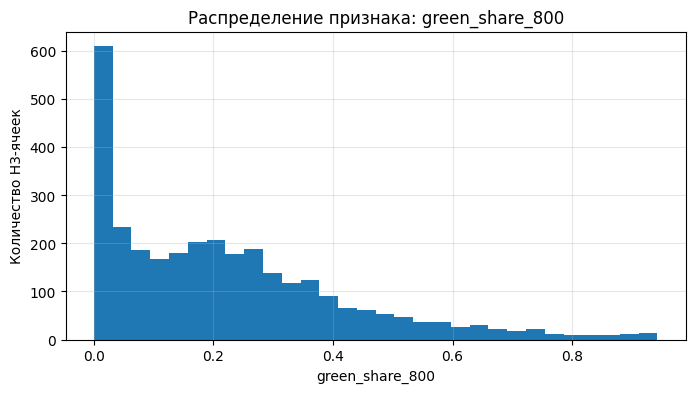

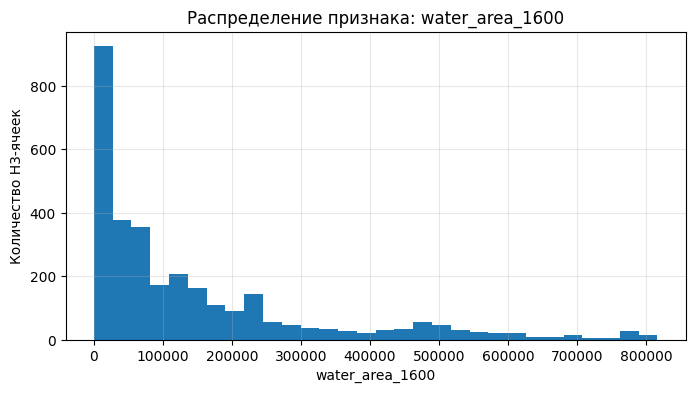

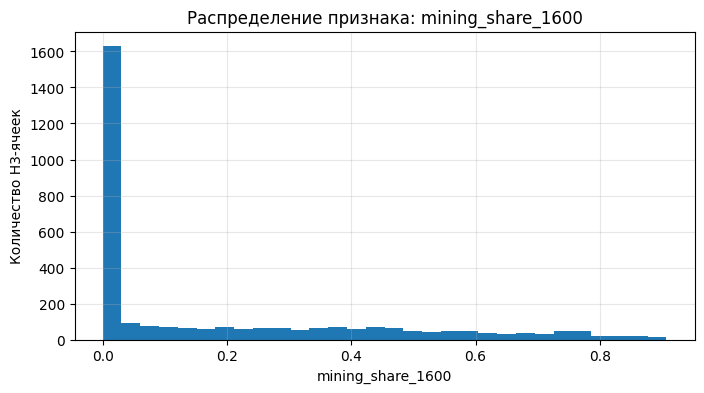

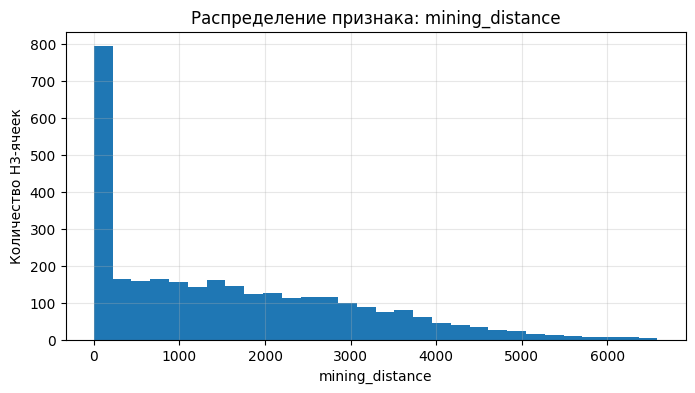

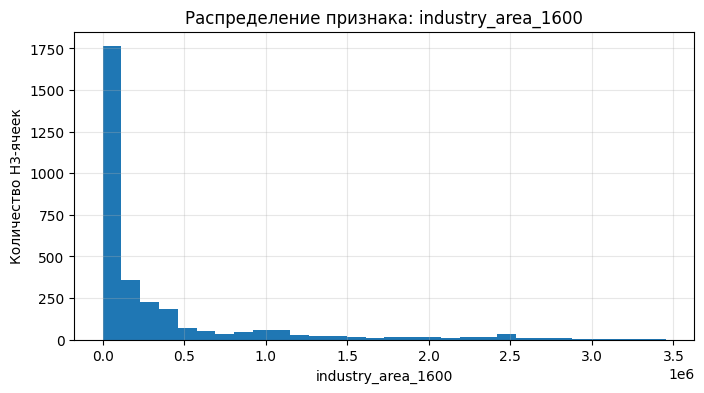

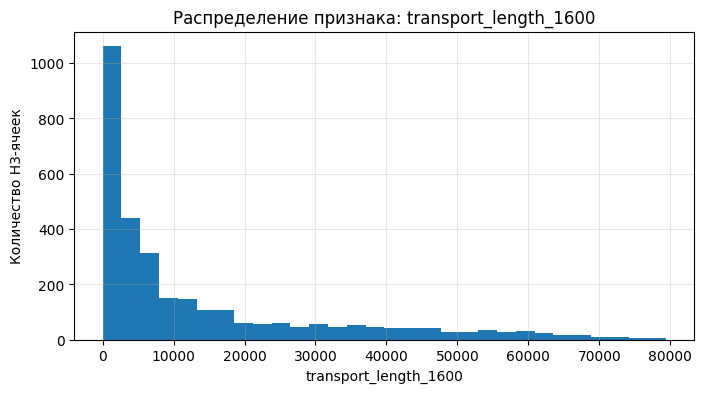

In [36]:
# Гистограммы распределения признаков.
# Они помогают увидеть выбросы и признаки, которые почти не меняются по территории.

for col in feature_cols:
    plt.figure(figsize=(8, 4))
    h3_features[col].hist(bins=30)
    plt.title(f"Распределение признака: {col}")
    plt.xlabel(col)
    plt.ylabel("Количество H3-ячеек")
    plt.grid(True, alpha=0.3)
    plt.show()

### ****Вывод по качеству признаков****

Ответьте:

1. Какие признаки хорошо различают территорию?
2. Какие признаки почти не меняются?
3. Есть ли признаки, которые следует исключить?
4. Нужно ли изменить радиус буфера или OSM-теги?
5. Какие признаки могут оказаться основными для будущей кластеризации?



**ВАШ ОТВЕТ:**

**1. Какие признаки хорошо различают территорию?**

Лучше всего территорию различают `mining_share_1600`, `mining_distance` и `green_share_800`. Они показывают, где находятся карьеры и отвалы, насколько далеко от них расположены участки и сколько вокруг зелёных зон. Остальные признаки тоже полезны, так как помогают выделить промышленные зоны, водоёмы и дороги.

**2. Какие признаки почти не меняются?**

Таких признаков нет. Все шесть признаков имеют достаточно большой разброс значений. Например, на одних участках почти нет промышленных объектов или водоёмов, а на других их площадь достаточно большая.

**3. Есть ли признаки, которые следует исключить?**

Пока исключать признаки не нужно, так как все они содержат полезную информацию. Но после корреляционного анализа некоторые признаки могут оказаться сильно связаны между собой. Особенно стоит проверить `mining_share_1600` и `mining_distance`.

**4. Нужно ли изменить радиус буфера или OSM-теги?**

На данный момент менять ничего не нужно, так как все признаки имеют нормальное распределение значений для исследуемой территории. При загрузке данных возникала ошибка сервера Overpass, из-за которой некоторые слои были пустыми. После повторной загрузки проблема решилась.

**5. Какие признаки могут оказаться основными для кластеризации?**

Основными будут `mining_share_1600`, `mining_distance` и `green_share_800`, так как они лучше всего показывают различия между промышленными и природными территориями. Остальные признаки помогут более подробно разделить участки на группы.

Перед кластеризацией также потребуется масштабировать признаки, поскольку они измеряются в разных единицах и сильно отличаются по значениям.



---

# ****Часть 5. Подготовка данных к кластеризации****

## ****5.1. Почему нельзя сразу запускать кластеризацию****

Алгоритмы кластеризации обычно работают с расстояниями между объектами. Если один признак измеряется в метрах, другой в квадратных метрах, а третий в количестве объектов, то без масштабирования признаки с большими численными значениями могут искусственно доминировать.

Поэтому нужно:

1. выбрать признаки для кластеризации;
2. обработать пропуски и бесконечные значения;
3. масштабировать признаки;
4. проверить корреляции;
5. решить, включать ли интегральный индекс или кластеризовать только отдельные признаки.

## ****5.2. Важное замечание про интегральный индекс****

Интегральный индекс экологического благополучия можно рассчитать, но не всегда стоит включать его в кластеризацию.

Почему:

- индекс уже является свёрткой признаков;
- если добавить индекс вместе с исходными признаками, он может дублировать информацию;
- кластеры могут отражать не структуру признаков, а вашу формулу индекса.

Рекомендуемый подход:

- для кластеризации используйте **отдельные признаки**;
- индекс можно использовать для интерпретации и сравнения кластеров;
- если вы включаете индекс в кластеризацию, обязательно объясните зачем.

In [37]:
# Выберите признаки для кластеризации.
# Можно начать со всех рассчитанных признаков, но затем исключить слабые или дублирующие.

CLUSTER_FEATURES = feature_cols.copy()

X_raw = h3_features[CLUSTER_FEATURES].replace([np.inf, -np.inf], np.nan).copy()

# Для distance-признаков пропуски можно заменить максимальным расстоянием или медианой.
# Здесь используется простая стратегия: заполнить пропуски нулями.
# Подумайте, подходит ли она для ваших данных.
X_raw = X_raw.fillna(0)

print("Признаки для кластеризации:")
print(CLUSTER_FEATURES)
X_raw.head()

Признаки для кластеризации:
['green_share_800', 'water_area_1600', 'mining_share_1600', 'mining_distance', 'industry_area_1600', 'transport_length_1600']


,green_share_800,water_area_1600,mining_share_1600,mining_distance,industry_area_1600,transport_length_1600
0,0.246211,124516.280476,0.000000,1917.408949,88749.380520,1071.519038
1,0.138044,254405.323026,0.481972,0.000000,325333.850922,8696.944610
2,0.000000,224737.315882,0.580339,0.000000,960559.286002,14054.620089
3,0.504115,0.000000,0.000000,3232.685974,0.000000,2093.198583
4,0.340415,7268.982835,0.000000,3652.107246,42952.190090,0.000000


## ****5.3. Корреляция признаков****

Если два признака почти полностью совпадают, один из них можно исключить. Например, `green_area_800` и `green_share_800` часто могут быть близко связаны.

Корреляция не означает, что признак плохой. Она показывает, что признаки могут нести похожую информацию.

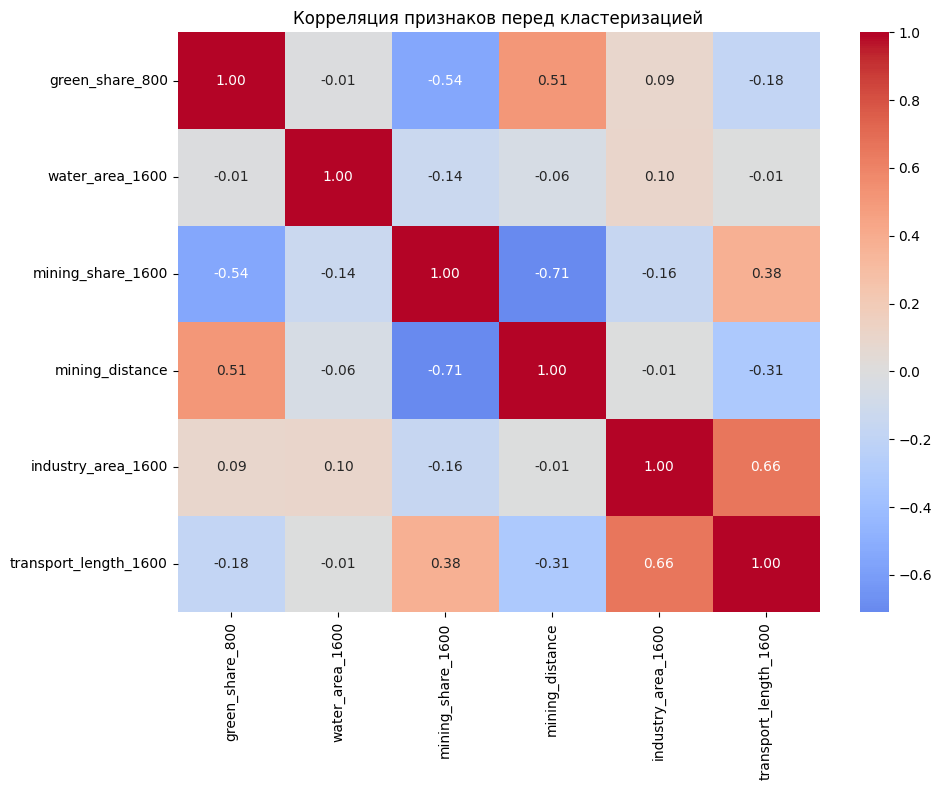

In [38]:
# Корреляционная матрица признаков

corr = X_raw.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Корреляция признаков перед кластеризацией")
plt.tight_layout()
plt.show()

### ****Решение по признакам****

Заполните после анализа корреляций.

1. Какие признаки вы оставляете для кластеризации?
2. Какие признаки исключаете и почему?
3. Есть ли признаки, которые дублируют друг друга?
4. Есть ли признаки, которые слишком слабо представлены в данных?



**ВАШ ОТВЕТ:**

**1. Какие признаки оставлены для кластеризации?**

Для кластеризации оставлены все шесть признаков: `green_share_800`, `water_area_1600`, `mining_share_1600`, `mining_distance`, `industry_area_1600` и `transport_length_1600`. Все они содержат полезную информацию о территории, а слишком высокой корреляции между ними нет.

**2. Какие признаки исключены и почему?**

Ни один признак не был исключён. Самая сильная связь наблюдается между `mining_share_1600` и `mining_distance` (−0,71), но они показывают разные характеристики: один — долю нарушенных земель, другой — расстояние до них. Также связаны `industry_area_1600` и `transport_length_1600` (0,66), поскольку рядом с промышленными объектами часто проходят дороги.

**3. Есть ли признаки, которые дублируют друг друга?**

Полностью дублирующих признаков нет. Некоторые признаки связаны между собой, например, чем ближе участок к карьеру, тем обычно меньше зелёных зон. Но каждый признак показывает свою характеристику территории, поэтому все они оставлены.

**4. Есть ли признаки, которые слишком слабо представлены в данных?**

Таких признаков нет. У всех признаков достаточно значений для анализа. Больше всего нулевых значений у `mining_share_1600` — около 39%, но это связано с тем, что не все участки находятся рядом с карьером и отвалами.

In [40]:
# Если после анализа корреляций вы решили изменить набор признаков,
# отредактируйте список ниже.

CLUSTER_FEATURES = [
    "green_share_800",
    "water_area_1600",
    "mining_share_1600",
    "mining_distance",
    "industry_area_1600",
    "transport_length_1600",
]

X_raw = h3_features[CLUSTER_FEATURES].replace([np.inf, -np.inf], np.nan).fillna(0)
print("Признаков для кластеризации:", len(CLUSTER_FEATURES), "| пропусков:", int(X_raw.isna().sum().sum()))

Признаков для кластеризации: 6 | пропусков: 0


## ****5.4. Масштабирование признаков****

Можно использовать два популярных варианта:

- `MinMaxScaler` — приводит признаки к диапазону от 0 до 1. Удобен для интерпретации.
- `StandardScaler` — приводит признаки к среднему 0 и стандартному отклонению 1. Часто полезен для K-means и PCA.

Выберите один вариант и объясните его.

In [41]:
# ЗАДАНИЕ: выберите scaler_type: "minmax" или "standard".

scaler_type = "minmax"

if scaler_type == "minmax":
    scaler = MinMaxScaler()
elif scaler_type == "standard":
    scaler = StandardScaler()
else:
    raise ValueError("scaler_type должен быть 'minmax' или 'standard'")

X_scaled = scaler.fit_transform(X_raw)
X_scaled_df = pd.DataFrame(X_scaled, columns=CLUSTER_FEATURES, index=h3_features.index)

print("Размерность матрицы для кластеризации:", X_scaled.shape)
X_scaled_df.head()

Размерность матрицы для кластеризации: (3110, 6)


,green_share_800,water_area_1600,mining_share_1600,mining_distance,industry_area_1600,transport_length_1600
0,0.261206,0.152436,0.000000,0.291232,0.025682,0.013492
1,0.146451,0.311449,0.531300,0.000000,0.094146,0.109508
2,0.000000,0.275129,0.639736,0.000000,0.277968,0.176969
3,0.534818,0.000000,0.000000,0.491007,0.000000,0.026357
4,0.361148,0.008899,0.000000,0.554712,0.012430,0.000000


### ****Обоснование масштабирования****

1. Какой способ масштабирования вы выбрали?
2. Почему он подходит для ваших признаков?
3. Есть ли признаки с выбросами, которые могут повлиять на масштабирование?



**ВАШ ОТВЕТ:**

**1. Какой способ масштабирования выбран?**

Для масштабирования выбран `MinMaxScaler`, который приводит значения всех признаков к диапазону от 0 до 1.

**2. Почему он подходит для этих признаков?**

Этот способ подходит, потому что признаки измеряются в разных единицах: метрах, квадратных метрах и долях. Без масштабирования признаки с большими значениями могли бы сильнее влиять на кластеризацию.

После масштабирования все признаки находятся в одном диапазоне, поэтому их удобнее сравнивать между собой. Также такой способ будет использоваться при расчёте экологического индекса.

**3. Есть ли признаки с выбросами, которые могут повлиять на масштабирование?**

Да, у `industry_area_1600`, `water_area_1600` и `transport_length_1600` встречаются очень большие значения по сравнению с остальными. Например, площадь промышленных зон в некоторых ячейках намного больше средней.

`MinMaxScaler` чувствителен к таким значениям, поэтому после масштабирования многие ячейки могут получить небольшие значения. Но в целом этот способ подходит для наших данных. В дальнейшем можно будет сравнить результаты с `StandardScaler`.



---

# ****Часть 6. Интегральный индекс экологического благополучия****

## ****6.1. Зачем считать индекс, если дальше будет кластеризация****

Индекс нужен не для замены кластеризации, а для дополнительной интерпретации. Он помогает понять, какие кластеры в среднем более благополучны, а какие более проблемны.

Для индекса важно направление влияния:

- позитивные признаки: чем больше, тем лучше;
- негативные признаки: чем больше, тем хуже, поэтому их нужно инвертировать;
- расстояние требует отдельного осмысления: расстояние до парка — чем меньше, тем лучше; расстояние до промзоны — чем больше, тем лучше.

## ****6.2. Пример логики индекса****

Допустим, признаки уже нормализованы в диапазоне `[0, 1]`.

Пример:



```python
index = (
    0.30 * norm_green_area +
    0.15 * norm_water_area +
    0.25 * (1 - norm_industry_area) +
    0.20 * (1 - norm_roads_length) +
    0.10 * (1 - norm_waste_count)
)
```



Веса должны суммироваться к 1. Но сами веса — это ваше исследовательское решение. Его нужно обосновать.

### ****Таблица весов для индекса****

| Признак | Вес | Направление влияния | Почему такой вес |
|---|---:|---|---|
| `mining_share_1600` | 0,25 | − (инвертируется) | Главный источник экологического воздействия на территории: карьер, отвалы и хвостохранилище дают пыль, изменённый рельеф и загрязнение почв и вод. Поэтому признак получает наибольший вес |
| `mining_distance` | 0,15 | + (чем дальше, тем лучше) | Дополняет долю нарушенных земель: различает ячейки, удалённые от комбината более чем на 1600 м. Вес меньше, чем у доли, потому что признаки связаны (корреляция −0,71) и вместе дают горнодобывающему фактору 0,40 — без чрезмерного двойного учёта |
| `green_share_800` | 0,20 | + | Основной позитивный фактор: растительность задерживает пыль, снижает шум и улучшает микроклимат в пределах пешей доступности. Наибольший вес среди позитивных признаков |
| `industry_area_1600` | 0,15 | − (инвертируется) | Нагрузка от обогатительной фабрики и промзон. Вес ниже, чем у горнодобывающего фактора, так как промышленные территории занимают меньшую площадь и сосредоточены в отдельных зонах |
| `transport_length_1600` | 0,15 | − (инвертируется) | Шум, выбросы и пыль от автомобильного и железнодорожного транспорта. Вес равен промышленному: эти признаки связаны (корреляция 0,66) и вместе описывают производственно-транспортную нагрузку |
| `water_area_1600` | 0,10 | + | Водоёмы улучшают микроклимат, но их влияние на экологическую ситуацию слабее, чем у растительности, а часть водоёмов рядом с промплощадками может быть технической. Поэтому вес наименьший |
| **Итого** | **1,00** | | |

In [42]:
# Создаём нормализованную таблицу именно для индекса.
# Даже если для кластеризации вы выбрали StandardScaler, для индекса удобнее использовать MinMaxScaler.

index_scaler = MinMaxScaler()
X_index_norm = pd.DataFrame(
    index_scaler.fit_transform(h3_features[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0)),
    columns=feature_cols,
    index=h3_features.index
)

# Направление влияния берём из FEATURE_RECIPES.
direction_by_feature = {recipe["feature"]: recipe["direction"] for recipe in FEATURE_RECIPES}

# Веса признаков в индексе экологического благополучия.
# Горнодобывающее воздействие — 0.40, природный потенциал — 0.30,
# производственно-транспортная нагрузка — 0.30.
weights = {
    "mining_share_1600": 0.25,      # (-) доля нарушенных земель — главный негативный фактор
    "mining_distance": 0.15,        # (+) удалённость от карьера и отвалов
    "green_share_800": 0.20,        # (+) доля зелёных зон
    "industry_area_1600": 0.15,     # (-) площадь промзон
    "transport_length_1600": 0.15,  # (-) протяжённость дорог и железнодорожных путей
    "water_area_1600": 0.10,        # (+) площадь водоёмов
}

print("Сумма весов:", round(sum(weights.values()), 6))
assert abs(sum(weights.values()) - 1.0) < 1e-6, "Сумма весов должна быть равна 1"

Сумма весов: 1.0


In [43]:
def calculate_environmental_index(X_norm, weights, direction_by_feature):
    score = pd.Series(0.0, index=X_norm.index)

    for feature, weight in weights.items():
        values = X_norm[feature]
        direction = direction_by_feature.get(feature, "mixed")

        if direction == "+":
            score += weight * values
        elif direction == "-":
            score += weight * (1 - values)
        else:
            # Для mixed-признаков решение должен принять исследователь.
            # Здесь используем значения напрямую, но лучше явно переопределить логику.
            score += weight * values

    return score

h3_features["eco_index"] = calculate_environmental_index(
    X_index_norm,
    weights,
    direction_by_feature
)

h3_features[["eco_index"] + list(weights.keys())].head()

,eco_index,mining_share_1600,mining_distance,green_share_800,industry_area_1600,transport_length_1600,water_area_1600
0,0.655293,0.000000,1917.408949,0.246211,88749.380520,1071.519038,124516.280476
1,0.447062,0.481972,0.000000,0.138044,325333.850922,8696.944610,254405.323026
2,0.349338,0.580339,0.000000,0.000000,960559.286002,14054.620089,224737.315882
3,0.726661,0.000000,3232.685974,0.504115,0.000000,2093.198583,0.000000
4,0.704462,0.000000,3652.107246,0.340415,42952.190090,0.000000,7268.982835


### ****Обоснование индекса****

1. Какие признаки вошли в индекс?
2. Почему вы выбрали именно такие веса?
3. Какие признаки были инвертированы и почему?
4. Какие ограничения есть у вашего индекса?
5. Будете ли вы включать индекс в кластеризацию или использовать только для интерпретации?

**ВАШ ОТВЕТ:**

**1. Какие признаки вошли в индекс?**

В индекс вошли все шесть признаков. К положительным относятся доля зелёных зон, площадь водоёмов и расстояние до нарушенных земель. К отрицательным — доля нарушенных земель, площадь промышленных зон и протяжённость дорог.

Все признаки приведены к диапазону от 0 до 1. Чем выше значение индекса, тем лучше экологическая ситуация на участке.

**2. Почему выбраны такие веса?**

Веса выбраны в зависимости от того, насколько сильно каждый фактор может влиять на экологическую ситуацию.

Наибольший вес (0,40) получили признаки, связанные с добычей полезных ископаемых, так как карьер и отвалы оказывают основное воздействие на территорию.

Зелёные зоны и водоёмы получили общий вес 0,30, поскольку они положительно влияют на окружающую среду. Промышленные зоны и транспорт также получили 0,30, так как являются дополнительными источниками загрязнения.

**3. Какие признаки инвертированы и почему?**

Инвертированы три признака: `mining_share_1600`, `industry_area_1600` и `transport_length_1600`.

Это сделано потому, что большие значения этих признаков означают более высокую нагрузку на окружающую среду. После инверсии они будут уменьшать экологический индекс, а не увеличивать его.

**4. Какие ограничения есть у индекса?**

Главное ограничение заключается в том, что веса выбраны самостоятельно, поэтому результат может измениться при других весах.

Также индекс рассчитывается на основе данных OSM, которые могут быть неполными или неточными. Он не учитывает реальные измерения загрязнения воздуха, воды и почвы, направление ветра и другие факторы.

Кроме того, на результат могут влиять слишком большие значения отдельных признаков и выбранные радиусы буферов.

Поэтому индекс даёт только примерную оценку экологической ситуации.

**5. Будет ли индекс включён в кластеризацию?**

Нет, индекс не будет использоваться при кластеризации, так как он уже рассчитан на основе тех же шести признаков. Его добавление привело бы к повторному учёту одних и тех же данных.

Индекс будет использоваться после кластеризации, чтобы сравнить полученные группы территорий и определить, какие из них наиболее и наименее экологически благополучны.

In [44]:
# Карта индекса экологического благополучия

eco_map = leafmap.Map(center=[(south + north) / 2, (west + east) / 2], zoom=11)  # Создание интерактивной карты с центром в середине bbox
eco_map.add_data(  # Добавление слоя данных с хороплет-визуализацией
    h3_features.to_crs("EPSG:4326"),  # Перепроецирование H3-сетки в WGS84 для отображения
    column="eco_index",  # Столбец для раскраски (индекс экологического благополучия)
    cmap="RdYlGn",  # Цветовая палитра: красный → жёлтый → зелёный (низкий → высокий)
    legend_title="Eco index",  # Заголовок легенды
    layer_name="Индекс экологического благополучия",  # Название слоя в панели управления
    style={"weight": 0, "fillOpacity": 0.8},  # weight=0 убирает границы, fillOpacity — прозрачность заливки
)  # Конец добавления слоя
eco_map  # Отображение карты в Jupyter Notebook

Map(center=[52.33, 35.4525], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom…

---

# ****Часть 7. Выбор числа кластеров****

## ****7.1. Почему число кластеров нужно выбирать осмысленно****

Для K-means, агломеративной и спектральной кластеризации нужно заранее задать число кластеров `k`.

Но `k` — это не просто число из графика. Оно должно быть связано с вашей задачей:

- слишком мало кластеров — разные типы территорий сольются;
- слишком много кластеров — результат станет трудно интерпретировать;
- хорошее `k` обычно даёт не только приемлемые метрики, но и понятные профили кластеров.

## ****7.2. Метрики для выбора `k`****

| Метрика | Как читать |
|---|---|
| Inertia / метод локтя | ищем точку, после которой улучшение становится слабым |
| Silhouette Score | выше — лучше, но не всегда гарантирует содержательность |
| Calinski–Harabasz | выше — лучше разделение и компактность |
| Davies–Bouldin | ниже — лучше |



Рассчитанные метрики дают лишь ориентир для выбора количества кластеров. Финальное число `k` необходимо определить после анализа сбалансированности полученных групп и содержательной корректности разделения.

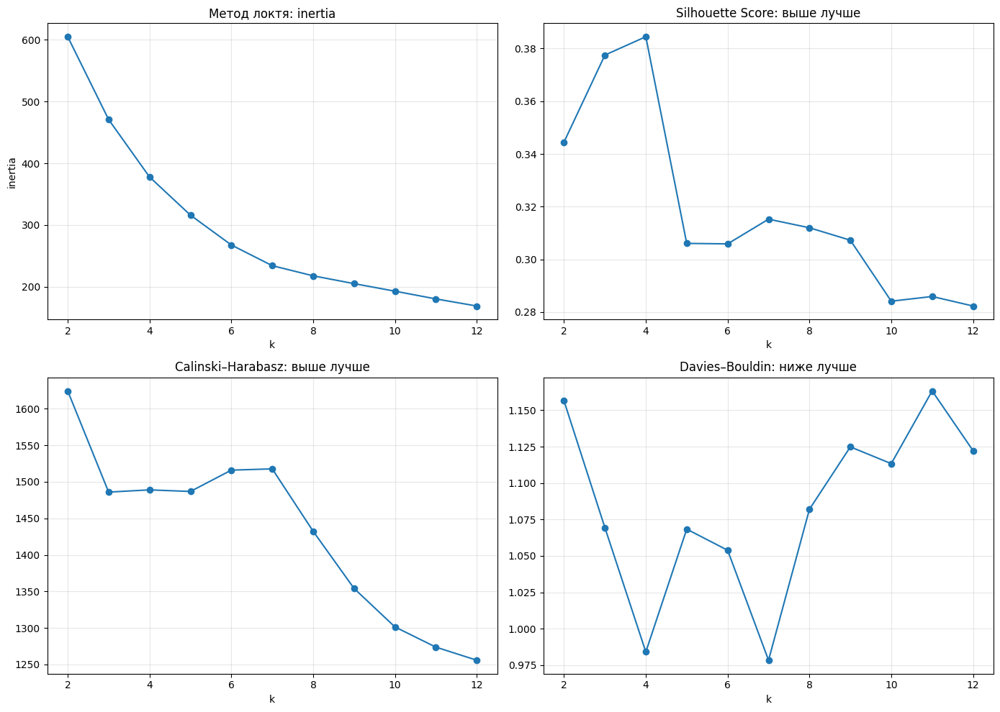

Предложение по метрикам:
Метод локтя: 6
Максимальный silhouette: 4
Максимальный Calinski–Harabasz: 2
Минимальный Davies–Bouldin: 7


,k,inertia,silhouette,calinski_harabasz,davies_bouldin
0,2,605.044237,0.344505,1624.506325,1.156379
1,3,470.879298,0.377508,1485.977842,1.069347
2,4,377.858479,0.384471,1489.013130,0.984060
3,5,316.008390,0.306064,1486.839180,1.068353
4,6,267.655382,0.305885,1516.054339,1.053875
5,7,234.139329,0.315255,1517.782090,0.978373
6,8,217.684356,0.311993,1432.347201,1.082004
7,9,205.039107,0.307272,1354.071177,1.124839
8,10,192.817896,0.284136,1301.348276,1.113325
9,11,180.290365,0.285927,1273.703230,1.163244


In [45]:
def find_optimal_clusters(X, max_k=12, random_state=42):  # Функция поиска оптимального числа кластеров K-means
    """
    Сравнение разных k для K-means по нескольким метрикам.
    """
    n_samples = X.shape[0]  # Количество наблюдений в датасете
    max_k = min(max_k, n_samples - 1)  # Ограничение max_k числом наблюдений минус 1
    k_range = range(2, max_k + 1)  # Диапазон k от 2 до max_k (k=1 не имеет смысла для кластеризации)

    rows = []  # Список для накопления метрик по каждому k
    inertias = []  # Список значений inertia (для метода локтя)

    for k in k_range:  # Итерация по всем значениям k
        model = KMeans(n_clusters=k, random_state=random_state, n_init=10)  # Создание модели K-means с 10 инициализациями
        labels = model.fit_predict(X)  # Обучение модели и получение меток кластеров

        inertia = model.inertia_  # Сумма квадратов расстояний до центроидов (WCSS)
        inertias.append(inertia)  # Сохранение inertia для текущего k

        rows.append({  # Добавление словаря с метриками для текущего k
            "k": k,  # Число кластеров
            "inertia": inertia,  # Inertia (внутрикластерная сумма квадратов)
            "silhouette": silhouette_score(X, labels),  # Silhouette: [-1, 1], выше — лучше
            "calinski_harabasz": calinski_harabasz_score(X, labels),  # Calinski-Harabasz: выше — лучше
            "davies_bouldin": davies_bouldin_score(X, labels)  # Davies-Bouldin: ниже — лучше
        })  # Конец словаря метрик

    metrics_df = pd.DataFrame(rows)  # Преобразование списка в DataFrame

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))  # Создание сетки 2×2 для графиков

    axes[0, 0].plot(metrics_df["k"], metrics_df["inertia"], marker="o")  # График метода локтя
    axes[0, 0].set_title("Метод локтя: inertia")  # Заголовок графика
    axes[0, 0].set_xlabel("k")  # Подпись оси X
    axes[0, 0].set_ylabel("inertia")  # Подпись оси Y
    axes[0, 0].grid(True, alpha=0.3)  # Включение сетки с прозрачностью

    axes[0, 1].plot(metrics_df["k"], metrics_df["silhouette"], marker="o")  # График Silhouette Score
    axes[0, 1].set_title("Silhouette Score: выше лучше")  # Заголовок графика
    axes[0, 1].set_xlabel("k")  # Подпись оси X
    axes[0, 1].grid(True, alpha=0.3)  # Включение сетки

    axes[1, 0].plot(metrics_df["k"], metrics_df["calinski_harabasz"], marker="o")  # График Calinski-Harabasz
    axes[1, 0].set_title("Calinski–Harabasz: выше лучше")  # Заголовок графика
    axes[1, 0].set_xlabel("k")  # Подпись оси X
    axes[1, 0].grid(True, alpha=0.3)  # Включение сетки

    axes[1, 1].plot(metrics_df["k"], metrics_df["davies_bouldin"], marker="o")  # График Davies-Bouldin
    axes[1, 1].set_title("Davies–Bouldin: ниже лучше")  # Заголовок графика
    axes[1, 1].set_xlabel("k")  # Подпись оси X
    axes[1, 1].grid(True, alpha=0.3)  # Включение сетки

    plt.tight_layout()  # Автоматическая подгонка отступов между графиками
    plt.show()  # Отображение всех графиков

    if KneeLocator is not None:  # Проверка доступности библиотеки kneed
        kl = KneeLocator(metrics_df["k"], metrics_df["inertia"], curve="convex", direction="decreasing")  # Автоматический поиск точки перегиба (локтя)
        elbow_k = kl.elbow  # Получение оптимального k по методу локтя
    else:  # Если kneed не установлен
        elbow_k = None  # Пропуск автоматического определения локтя

    print("Предложение по метрикам:")  # Вывод рекомендаций
    print("Метод локтя:", elbow_k)  # Оптимальный k по методу локтя
    print("Максимальный silhouette:", metrics_df.loc[metrics_df["silhouette"].idxmax(), "k"])  # k с лучшим Silhouette
    print("Максимальный Calinski–Harabasz:", metrics_df.loc[metrics_df["calinski_harabasz"].idxmax(), "k"])  # k с лучшим CH
    print("Минимальный Davies–Bouldin:", metrics_df.loc[metrics_df["davies_bouldin"].idxmin(), "k"])  # k с лучшим DB

    return metrics_df  # Возврат DataFrame со всеми метриками

k_metrics_df = find_optimal_clusters(X_scaled, max_k=12)

k_metrics_df

### ****Ваш выбор числа кластеров****

Не пишите просто «выбрал k=4, потому что так показала метрика». Объясните содержательно.

1. Какие значения `k` предложили разные метрики?
2. Где виден «локоть»?
3. Какое число кластеров кажется интерпретируемым для вашей территории?
4. Какой компромисс вы выбираете между качеством метрик и понятностью результата?



**ВАШ ОТВЕТ:**

**1. Какие значения k предложили разные метрики?**

Разные метрики предложили разное количество кластеров:

- Метод локтя — 6 кластеров.
- Silhouette Score — 4 кластера.
- Calinski–Harabasz — 2 кластера.
- Davies–Bouldin — 7 кластеров.

Два кластера для нашей задачи слишком мало, так как территория разделится только на промышленную и остальную часть. Поэтому лучше рассматривать варианты с большим количеством кластеров.

**2. Где виден «локоть»?**

На графике заметно, что до 4 кластеров ошибка уменьшается достаточно быстро, а затем снижение постепенно замедляется.

Метод автоматически определил локоть при k = 6, но чёткого перегиба на графике нет. Поэтому можно рассматривать значения от 4 до 7 кластеров.

**3. Какое число кластеров интерпретируемо для территории?**

Я считаю, что для нашей территории достаточно 4 кластеров, так как можно выделить основные типы участков:

- Карьер и отвалы.
- Промышленные и транспортные зоны.
- Лесные и природные территории.
- Городские и переходные территории.

Если выбрать 6–7 кластеров, разделение будет более подробным, но объяснить различия между некоторыми группами станет сложнее.

**4. Какой компромисс между качеством метрик и понятностью?**

В итоге выбрано **k = 4**, так как при этом значении Silhouette Score максимальный (0,384), а Davies–Bouldin (0,984) почти равен своему лучшему значению.

Кроме того, четыре кластера удобно анализировать и сравнивать между собой. Они соответствуют основным типам территорий, которые мы ожидаем увидеть.

In [46]:
# ЗАДАНИЕ: установите выбранное число кластеров после анализа метрик.

SELECTED_K = 4

## ****7.3. Подбор `eps` для DBSCAN****

DBSCAN не требует заранее задавать количество кластеров, но требует параметры:

- `eps` — радиус соседства;
- `min_samples` — минимальное число точек для образования плотной области.

Если `eps` слишком маленький, будет много шума. Если слишком большой — разные зоны сольются в один кластер.

Предложенный eps: 0.1534


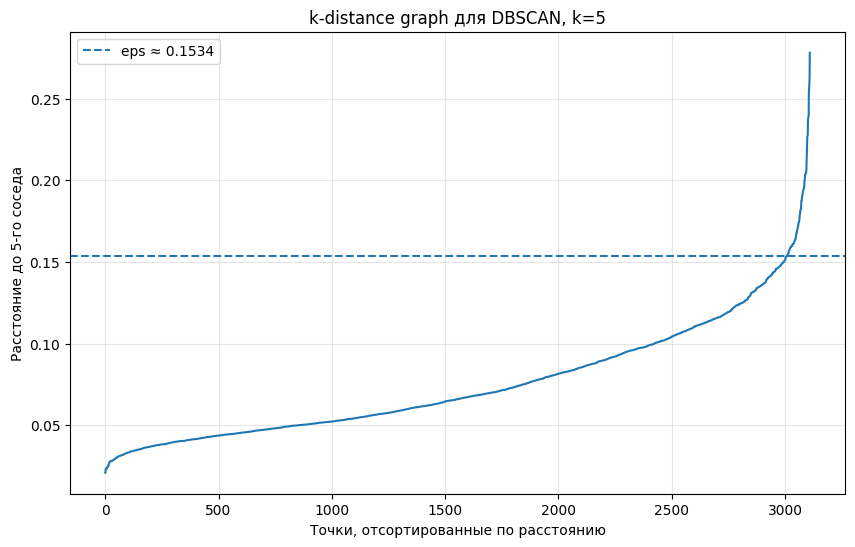

In [47]:
def find_optimal_eps(X, k=5):  # Функция поиска оптимального eps для DBSCAN по k-distance графику
    """
    Строит k-distance graph для выбора eps в DBSCAN.
    """
    neigh = NearestNeighbors(n_neighbors=k)  # Создание модели k ближайших соседей
    neigh.fit(X)  # Обучение модели на данных
    distances, _ = neigh.kneighbors(X)  # Получение расстояний до k ближайших соседей для каждой точки

    distances = np.sort(distances[:, k - 1])  # Сортировка расстояний до k-го соседа по возрастанию
    indices = np.arange(len(distances))  # Создание массива индексов для оси X графика

    eps_candidate = None  # Инициализация переменной для оптимального eps
    if KneeLocator is not None:  # Проверка доступности библиотеки kneed
        kl = KneeLocator(indices, distances, curve="convex", direction="increasing")  # Автоматический поиск точки перегиба (локтя) на графике
        if kl.knee is not None:  # Если локоть найден
            eps_candidate = distances[kl.knee]  # Получение значения eps в точке перегиба

    plt.figure(figsize=(10, 6))  # Создание фигуры для графика
    plt.plot(indices, distances)  # Построение k-distance графика
    plt.title(f"k-distance graph для DBSCAN, k={k}")  # Заголовок графика
    plt.xlabel("Точки, отсортированные по расстоянию")  # Подпись оси X
    plt.ylabel(f"Расстояние до {k}-го соседа")  # Подпись оси Y
    plt.grid(True, alpha=0.3)  # Включение сетки с прозрачностью

    if eps_candidate is not None:  # Если eps был найден автоматически
        plt.axhline(eps_candidate, linestyle="--", label=f"eps ≈ {eps_candidate:.4f}")  # Горизонтальная линия на уровне eps
        plt.legend()  # Отображение легенды
        print(f"Предложенный eps: {eps_candidate:.4f}")  # Вывод найденного eps
    else:  # Если автоматический поиск не удался
        eps_candidate = np.percentile(distances, 90)  # В случае неудачи: использование 90-го перцентиля расстояний
        print(f"Автоматический локоть не найден. Примерный eps по 90-му процентилю: {eps_candidate:.4f}")  # Информирование пользователя

    plt.show()  # Отображение графика
    return float(eps_candidate)  # Возврат оптимального eps как float

DBSCAN_MIN_SAMPLES = 5  # Минимальное число точек для формирования плотной области (MinPts); может быть изменён Вами вручную
DBSCAN_EPS = find_optimal_eps(X_scaled, k=DBSCAN_MIN_SAMPLES)  # Вызов функции для поиска eps; может быть изменён вручную после анализа графика

### ****Решение по DBSCAN****

1. Какой `eps` вы выбрали?
2. Почему выбранный `min_samples` подходит для ваших данных?
3. Что происходит, если немного увеличить или уменьшить `eps`?
4. Подходит ли DBSCAN для ваших данных по смыслу?



**ВАШ ОТВЕТ:**

**1. Какой eps выбран?**

Выбрано значение `eps = 0,1534`. Оно было определено автоматически по графику расстояний до ближайших соседей.

На графике видно, что до этого значения расстояния увеличиваются постепенно, а после начинают расти быстрее. Поэтому это значение подходит для разделения плотных групп и отдельных точек.

**2. Почему min_samples = 5 подходит?**

Выбрано `min_samples = 5`, так как для формирования плотной области достаточно пяти соседних точек.

Всего у нас 3110 ячеек, поэтому такое значение позволяет находить небольшие группы и при этом не слишком сильно реагировать на отдельные случайные точки.

**3. Что происходит при изменении eps?**

Если уменьшить `eps`, алгоритм будет выделять больше шумовых точек и может создать много небольших кластеров.

Если увеличить `eps`, больше точек будут объединяться между собой, из-за чего разные группы могут слиться в один большой кластер.

Поэтому важно подобрать значение, при котором кластеры будут достаточно хорошо разделяться.

**4. Подходит ли DBSCAN по смыслу?**

DBSCAN подходит для нашей задачи не совсем хорошо, так как признаки на территории изменяются постепенно и между участками нет чётких границ.

Из-за этого алгоритм может объединить большую часть ячеек в один кластер, а остальные определить как шум.

Но DBSCAN всё равно полезен, поскольку с его помощью можно найти необычные участки, которые сильно отличаются от остальных.

Окончательно оценить его работу можно будет после сравнения с другими алгоритмами кластеризации.



---

# ****Часть 8. Сравнение алгоритмов кластеризации****

## ****8.1. Как выбирать алгоритм****

Краткие ориентиры:

| Алгоритм | Когда подходит | Ограничения |
|---|---|---|
| K-means | ожидаются компактные группы, нужен простой интерпретируемый результат | требует `k`, чувствителен к масштабированию и выбросам |
| Агломеративная кластеризация | полезна для иерархической структуры, часто хорошо интерпретируется | тоже требует `k`, может быть медленной на больших данных |
| Спектральная кластеризация | может находить более сложные формы групп | вычислительно тяжелее, требует `k` |
| DBSCAN | ищет плотные области и шум | чувствителен к `eps`, плохо работает при разной плотности |
| HDBSCAN | более гибкая плотностная кластеризация | может давать слишком много мелких кластеров, требует интерпретации |

Ваша задача — не просто найти максимальную метрику, а выбрать алгоритм, который даёт **понятную экологическую типологию территории**.

## ****8.2. Вспомогательная функция оценки качества кластеризации****

Для DBSCAN и HDBSCAN возможна метка `-1`, которая означает шум. В расчёте метрик ниже шумовые точки исключаются из оценки, но их доля выводится отдельно.

In [48]:
def evaluate_clustering(X, labels, algorithm_name):  # Функция оценки качества кластеризации по нескольким метрикам
    labels = np.asarray(labels)  # Преобразование меток в numpy-массив для унификации
    noise_mask = labels == -1  # Маска шумовых точек (DBSCAN помечает шум как -1)
    n_noise = int(noise_mask.sum())  # Подсчёт количества шумовых точек
    noise_share = n_noise / len(labels) if len(labels) > 0 else 0  # Доля шума от общего числа точек

    if n_noise > 0:  # Если есть шумовые точки
        X_eval = X[~noise_mask]  # Данные без шума для расчёта метрик
        labels_eval = labels[~noise_mask]  # Метки без шума
    else:  # Если шума нет
        X_eval = X  # Используем все данные
        labels_eval = labels  # Используем все метки

    unique_clusters = sorted(set(labels_eval))  # Список уникальных кластеров (без шума)
    n_clusters = len(unique_clusters)  # Количество найденных кластеров

    metrics = {  # Словарь для хранения результатов оценки
        "algorithm": algorithm_name,  # Название алгоритма кластеризации
        "n_clusters": n_clusters,  # Число кластеров
        "n_noise": n_noise,  # Количество шумовых точек
        "noise_share": noise_share,  # Доля шума (0–1)
        "silhouette": np.nan,  # Silhouette Score (заполнится позже, если возможно)
        "calinski_harabasz": np.nan,  # Calinski-Harabasz Index (заполнится позже)
        "davies_bouldin": np.nan,  # Davies-Bouldin Index (заполнится позже)
    }  # Конец словаря метрик

    if n_clusters >= 2 and len(labels_eval) > n_clusters:  # Проверка: метрики требуют минимум 2 кластера и достаточно точек
        metrics["silhouette"] = silhouette_score(X_eval, labels_eval)  # Расчёт Silhouette: [-1, 1], выше — лучше
        metrics["calinski_harabasz"] = calinski_harabasz_score(X_eval, labels_eval)  # Расчёт CH: выше — лучше
        metrics["davies_bouldin"] = davies_bouldin_score(X_eval, labels_eval)  # Расчёт DB: ниже — лучше

    return metrics  # Возврат словаря с метриками

In [50]:
def run_clustering_suite(X_scaled, selected_k, dbscan_eps, dbscan_min_samples=5):  # Функция запуска нескольких алгоритмов кластеризации
    results = {}  # Словарь для хранения результатов всех алгоритмов

    # K-means
    kmeans = KMeans(n_clusters=selected_k, random_state=42, n_init=10)  # Создание модели K-means с заданным числом кластеров
    results["K-means"] = {  # Сохранение результатов K-means
        "model": kmeans,  # Обученная модель
        "labels": kmeans.fit_predict(X_scaled)  # Обучение и получение меток кластеров
    }  # Конец записи K-means

    # Агломеративная кластеризация
    agglom = AgglomerativeClustering(n_clusters=selected_k)  # Создание модели иерархической кластеризации (снизу вверх)
    results["Agglomerative"] = {  # Сохранение результатов агломеративной кластеризации
        "model": agglom,  # Обученная модель
        "labels": agglom.fit_predict(X_scaled)  # Обучение и получение меток кластеров
    }  # Конец записи Agglomerative

    # Спектральная кластеризация может быть медленной на больших выборках.
    if X_scaled.shape[0] <= 3500:  # Проверка размера данных (ограничение по производительности)
        spectral = SpectralClustering(  # Создание модели спектральной кластеризации
            n_clusters=selected_k,  # Число кластеров
            random_state=42,  # Фиксация случайности для воспроизводимости
            assign_labels="kmeans",  # Метод присвоения меток после построения графа
            affinity="nearest_neighbors"  # Тип матрицы сходства (по ближайшим соседям)
        )  # Конец инициализации SpectralClustering
        results["Spectral"] = {  # Сохранение результатов спектральной кластеризации
            "model": spectral,  # Обученная модель
            "labels": spectral.fit_predict(X_scaled)  # Обучение и получение меток кластеров
        }  # Конец записи Spectral
    else:  # Если данных слишком много
        print("SpectralClustering пропущен: слишком много H3-ячеек.")  # Информирование о пропуске

    # DBSCAN
    dbscan = DBSCAN(eps=dbscan_eps, min_samples=dbscan_min_samples)  # Создание модели DBSCAN с заданными eps и min_samples
    results["DBSCAN"] = {  # Сохранение результатов DBSCAN
        "model": dbscan,  # Обученная модель
        "labels": dbscan.fit_predict(X_scaled)  # Обучение и получение меток (шум помечается как -1)
    }  # Конец записи DBSCAN

    # HDBSCAN — если библиотека доступна.
    try:  # Попытка использовать HDBSCAN (не входит в sklearn)
        import hdbscan  # Импорт библиотеки hdbscan
        hdb = hdbscan.HDBSCAN(min_cluster_size=max(5, dbscan_min_samples))  # Создание модели HDBSCAN с минимальным размером кластера
        results["HDBSCAN"] = {  # Сохранение результатов HDBSCAN
            "model": hdb,  # Обученная модель
            "labels": hdb.fit_predict(X_scaled)  # Обучение и получение меток кластеров
        }  # Конец записи HDBSCAN
    except Exception as e:  # Обработка ошибки (библиотека не установлена)
        print("HDBSCAN пропущен:", e)  # Вывод причины пропуска

    return results  # Возврат словаря со всеми результатами

clustering_results = run_clustering_suite(  # Запуск всех алгоритмов кластеризации
    X_scaled=X_scaled,  # Масштабированные данные
    selected_k=SELECTED_K,  # Выбранное число кластеров (для K-means, Agglomerative, Spectral)
    dbscan_eps=DBSCAN_EPS,  # Радиус окрестности для DBSCAN
    dbscan_min_samples=DBSCAN_MIN_SAMPLES  # Минимум точек для ядра кластера (DBSCAN)
)  # Конец вызова функции

list(clustering_results.keys())  # Вывод списка использованных алгоритмов

['K-means', 'Agglomerative', 'Spectral', 'DBSCAN', 'HDBSCAN']

In [51]:
# Сравнение алгоритмов по метрикам

comparison_rows = []  # Список для накопления метрик по каждому алгоритму
for algorithm_name, result in clustering_results.items():  # Итерация по результатам всех алгоритмов
    metrics = evaluate_clustering(X_scaled, result["labels"], algorithm_name)  # Расчёт метрик качества для текущего алгоритма
    comparison_rows.append(metrics)  # Добавление словаря метрик в список

comparison_df = pd.DataFrame(comparison_rows).sort_values(  # Создание DataFrame и сортировка результатов
    by=["silhouette", "calinski_harabasz"],  # Сортировка по Silhouette, затем по Calinski-Harabasz
    ascending=[False, False]  # Оба показателя: чем выше — тем лучше
)  # Конец сортировки

comparison_df  # Вывод таблицы сравнения алгоритмов

,algorithm,n_clusters,n_noise,noise_share,silhouette,calinski_harabasz,davies_bouldin
0,K-means,4,0,0.000000,0.384471,1489.013130,0.984060
1,Agglomerative,4,0,0.000000,0.349140,1139.732472,1.006182
2,Spectral,4,0,0.000000,0.280715,1107.921167,1.284501
4,HDBSCAN,17,898,0.288746,-0.162609,60.926049,1.020282
3,DBSCAN,1,40,0.012862,NaN,NaN,NaN


### ****Анализ таблицы сравнения****

Ответьте:

1. Какой алгоритм дал лучшие метрики?
2. Какой алгоритм дал наиболее понятное число кластеров?
3. Есть ли алгоритмы, которые дали слишком много шума или слишком много кластеров?
4. Совпадает ли «лучший по метрике» алгоритм с «лучшим по смыслу»?
5. Какой алгоритм вы выбираете для итоговой интерпретации?



**ВАШ ОТВЕТ:**

_Замените этот текст своим анализом._

In [52]:
# ЗАДАНИЕ: выберите итоговый алгоритм вручную после анализа метрик и смысла кластеров.
# Возможные значения: ключи из clustering_results, например "K-means", "Agglomerative", "Spectral", "DBSCAN", "HDBSCAN".

BEST_ALGORITHM = "K-means"

best_labels = clustering_results[BEST_ALGORITHM]["labels"]
print("Выбранный алгоритм:", BEST_ALGORITHM)
print("Уникальные метки кластеров:", sorted(set(best_labels)))

Выбранный алгоритм: K-means
Уникальные метки кластеров: [np.int32(0), np.int32(1), np.int32(2), np.int32(3)]


---

# ****Часть 9. Визуализация и интерпретация кластеров****

## ****9.1. PCA-визуализация кластеров****

PCA помогает увидеть многомерные данные на двумерном графике. Это не карта, а проекция признакового пространства. Если кластеры на PCA-графике сильно перекрываются, это не всегда ошибка, но требует внимательной интерпретации.

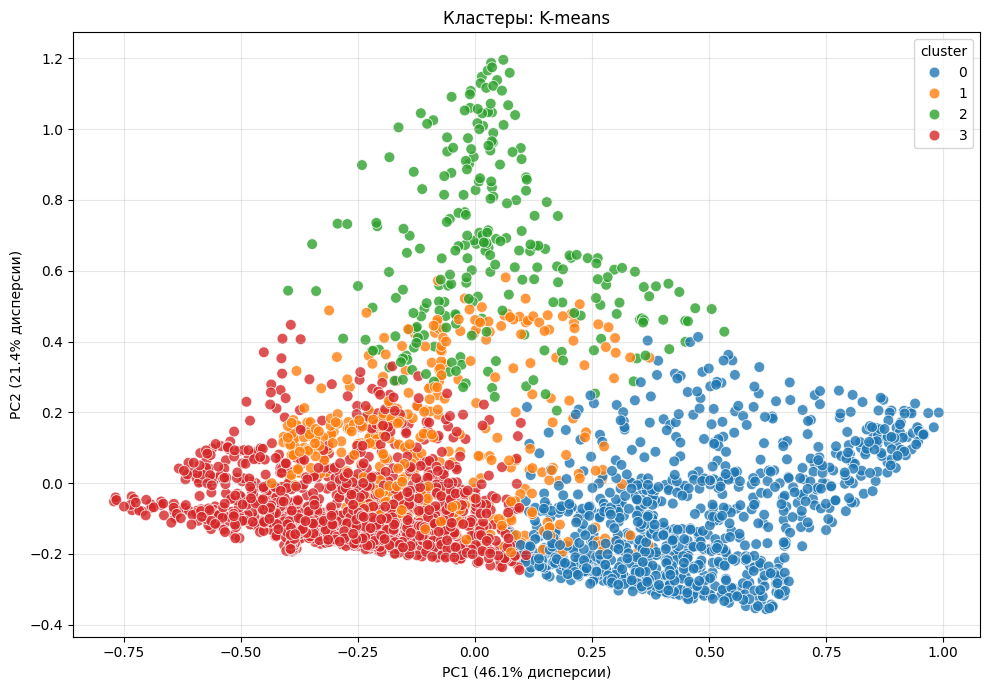

In [53]:
def plot_clusters_pca(X_scaled, labels, feature_names, title="Кластеры в пространстве PCA"):  # Функция визуализации кластеров в 2D через PCA
    pca = PCA(n_components=2, random_state=42)  # Создание модели PCA для снижения размерности до 2 компонент
    X_pca = pca.fit_transform(X_scaled)  # Обучение PCA и трансформация данных в 2D-пространство

    viz_df = pd.DataFrame({  # Создание DataFrame для визуализации
        "PC1": X_pca[:, 0],  # Первая главная компонента
        "PC2": X_pca[:, 1],  # Вторая главная компонента
        "cluster": labels  # Метки кластеров для раскраски точек
    })  # Конец создания DataFrame

    plt.figure(figsize=(10, 7))  # Создание фигуры заданного размера
    sns.scatterplot(data=viz_df, x="PC1", y="PC2", hue="cluster", palette="tab10", s=60, alpha=0.8)  # Построение scatter plot с раскраской по кластерам
    plt.title(title)  # Установка заголовка графика
    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} дисперсии)")  # Подпись оси X с долей объяснённой дисперсии
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} дисперсии)")  # Подпись оси Y с долей объяснённой дисперсии
    plt.grid(True, alpha=0.3)  # Включение сетки с прозрачностью
    plt.tight_layout()  # Автоматическая подгонка отступов
    plt.show()  # Отображение графика

    return viz_df, pca  # Возврат DataFrame с координатами и обученной модели PCA

pca_df, pca_model = plot_clusters_pca(  # Вызов функции визуализации
    X_scaled,  # Масштабированные данные
    best_labels,  # Метки лучшего алгоритма кластеризации
    CLUSTER_FEATURES,  # Список названий признаков
    title=f"Кластеры: {BEST_ALGORITHM}"  # Заголовок с названием алгоритма
)  # Конец вызова функции

## ****9.2. Профили кластеров****

Профиль кластера — это средние значения признаков внутри кластера. Именно по профилю мы понимаем, что означает каждый кластер.

Не называйте кластеры случайно. Название должно вытекать из признаков:

- высокая доля зелёных зон + мало дорог → «зелёные рекреационные территории»;
- много промзон + много дорог → «промышленно-транспортные зоны»;
- мало зелени + высокая транспортная нагрузка → «урбанизированные зоны экологического давления».

In [54]:
# Добавляем метки выбранного алгоритма в таблицу H3

h3_result = h3_features.copy()
h3_result["cluster"] = best_labels

# Профили кластеров по исходным признакам
cluster_profiles_raw = h3_result.groupby("cluster")[CLUSTER_FEATURES + ["eco_index"]].mean()
cluster_profiles_raw

,green_share_800,water_area_1600,mining_share_1600,mining_distance,industry_area_1600,transport_length_1600,eco_index
cluster,,,,,,,
0,0.056322,95257.260236,0.516528,116.924632,1.503033e+05,20287.540172,0.389086
1,0.226598,521453.038432,0.086959,1376.929972,3.813539e+05,12593.616511,0.628984
2,0.254061,125093.868096,0.072830,1708.154056,2.065262e+06,48180.814539,0.457419
3,0.313232,79215.163853,0.023656,2486.389016,1.535228e+05,4111.819526,0.661858


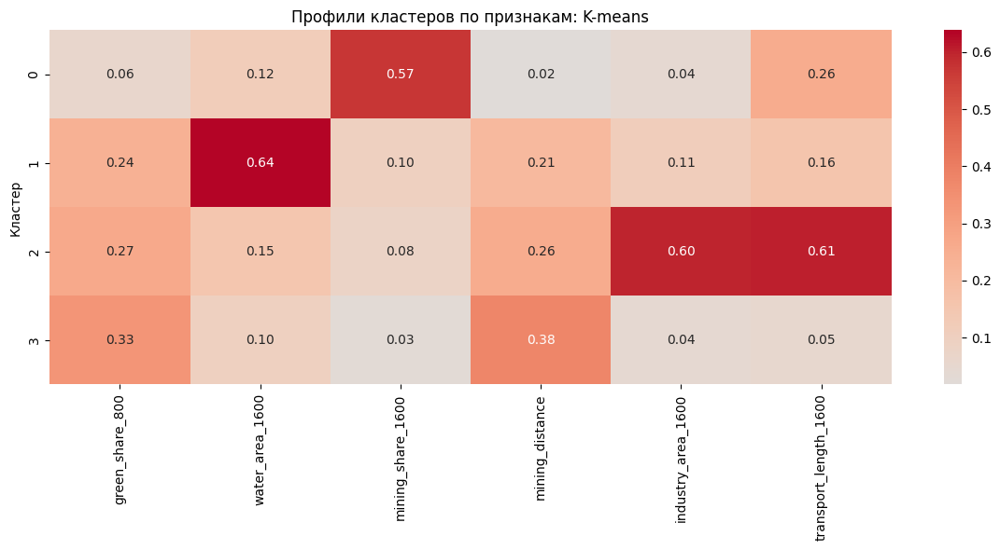

In [55]:
# Профили кластеров по масштабированным признакам

X_scaled_with_cluster = X_scaled_df.copy()
X_scaled_with_cluster["cluster"] = best_labels
cluster_profiles_scaled = X_scaled_with_cluster.groupby("cluster")[CLUSTER_FEATURES].mean()

plt.figure(figsize=(12, 6))
sns.heatmap(cluster_profiles_scaled, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title(f"Профили кластеров по признакам: {BEST_ALGORITHM}")
plt.ylabel("Кластер")
plt.tight_layout()
plt.show()

In [56]:
# Размеры кластеров

cluster_sizes = h3_result["cluster"].value_counts().sort_index().to_frame("n_cells")
cluster_sizes["share"] = cluster_sizes["n_cells"] / cluster_sizes["n_cells"].sum()
cluster_sizes

,n_cells,share
cluster,,
0,933,0.300000
1,402,0.129260
2,247,0.079421
3,1528,0.491318


### ****Интерпретация профилей кластеров****


| Кластер | Размер / доля | Какие признаки высокие | Какие признаки низкие | Предлагаемое название | Экологический смысл | Рекомендации |
|---|---|---|---|---|---|---|
| 0 | 933 / 30,0% | Большая доля нарушенных земель (0,52), много дорог и ж/д путей (около 20 км) | Мало зелёных зон (0,06), небольшое расстояние до карьера (около 117 м) | Карьер и отвалы | Наиболее неблагополучная территория (индекс 0,39). Мало растительности, высокая запылённость из-за добычи и транспорта | Восстановление нарушенных земель, снижение запылённости, посадка защитных лесополос |
| 1 | 402 / 12,9% | Большая площадь водоёмов (около 0,52 км²), умеренное количество зелени (0,23) | Небольшая доля нарушенных земель (0,09), умеренная промышленная нагрузка | Территории у водоёмов | Относительно благополучная территория (индекс 0,63). Водоёмы улучшают экологическую ситуацию, но некоторые могут быть техническими | Контроль качества воды, благоустройство берегов, защита водоёмов от загрязнения |
| 2 | 247 / 7,9% | Большая площадь промзон (около 2,1 млн м²), много дорог и ж/д путей (около 48 км) | Мало нарушенных земель (0,07) и водоёмов | Промышленно-транспортная зона | Высокая нагрузка на окружающую среду (индекс 0,46). Основные проблемы — выбросы предприятий, шум и транспорт | Озеленение промзон, контроль выбросов, создание защитных зон вдоль дорог |
| 3 | 1528 / 49,1% | Много зелёных зон (0,31), большое расстояние до карьера (около 2,5 км) | Мало нарушенных земель (0,02), промзон и дорог (около 4 км) | Природные и сельские территории | Наиболее благополучная территория (индекс 0,66). Много растительности и небольшое влияние промышленности | Сохранение лесов, ограничение расширения промзон, развитие природных зон отдыха |


## ****9.3. Карта кластеров****

Карта помогает проверить, имеют ли кластеры пространственный смысл.

Вопросы для проверки:

- расположены ли кластеры компактно или хаотично?
- совпадают ли они с ожидаемыми зонами города?
- есть ли кластеры, которые выглядят как шум?
- объяснимы ли границы кластеров через выбранные признаки?

In [58]:
# Карта кластеров: каждый кластер — отдельный слой со своим цветом.
# add_data с column="cluster" разбивает номера кластеров на интервалы как непрерывную величину
# и объединяет соседние кластеры в один цвет, поэтому рисуем кластеры по отдельности.
cluster_names = {  # Содержательные названия кластеров (по профилям из 9.2)
    0: "0 — Зона горнодобывающего воздействия",
    1: "1 — Территории у водоёмов",
    2: "2 — Промышленно-транспортная зона",
    3: "3 — Природные и сельские территории",
}
cluster_colors = {0: "#8c564b", 1: "#1f77b4", 2: "#d62728", 3: "#2ca02c"}  # Цвета кластеров

cluster_map = leafmap.Map(center=[(south + north) / 2, (west + east) / 2], zoom=12)  # Интерактивная карта с центром в середине bbox
h3_result_wgs = h3_result.to_crs("EPSG:4326")  # Перепроецирование H3-сетки в WGS84 для отображения

for cl in sorted(h3_result_wgs["cluster"].unique()):  # Отдельный слой для каждого кластера
    cl = int(cl)
    cluster_map.add_gdf(
        h3_result_wgs.loc[h3_result_wgs["cluster"] == cl, ["geometry"]],  # Ячейки текущего кластера
        layer_name=cluster_names.get(cl, f"Кластер {cl}"),  # Название слоя в панели управления
        style={"color": cluster_colors.get(cl, "gray"), "fillColor": cluster_colors.get(cl, "gray"),
               "weight": 0, "fillOpacity": 0.7},  # Цвет заливки без границ ячеек
    )

cluster_map.add_legend(  # Легенда с названиями кластеров
    title=f"Кластеры: {BEST_ALGORITHM}",
    legend_dict={cluster_names[k]: cluster_colors[k] for k in cluster_names},
)
cluster_map  # Отображение карты

Map(center=[52.33, 35.4525], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom…

### ****Пространственная интерпретация кластеров****

Ответьте:

1. Какие кластеры расположены компактно?
2. Какие кластеры разбросаны по территории?
3. Есть ли связь кластеров с промышленными зонами, реками, магистралями, парками?
4. Какие кластеры имеют высокий/низкий `eco_index`?
5. Есть ли результаты, которые выглядят странно? Чем это может объясняться?



**ВАШ ОТВЕТ:**

**1. Какие кластеры расположены компактно?**

Компактно расположены кластеры 0, 2 и 3.

- Кластер 0 находится в районе карьера, отвалов и хвостохранилища МГОК.
- Кластер 2 занимает промышленные зоны города и территорию обогатительной фабрики.
- Кластер 3 занимает большую часть территории вокруг города и комбината.

**2. Какие кластеры разбросаны по территории?**

Наиболее разбросан кластер 1, который связан с водоёмами. Его участки находятся в разных частях территории, например, около Железногорского водохранилища и прудов рядом с промышленными зонами.

Это объясняется тем, что водоёмы расположены отдельно друг от друга.

**3. Есть ли связь кластеров с объектами территории?**

Да, полученные кластеры хорошо соответствуют основным объектам территории:

- Кластер 0 — карьер, отвалы и хвостохранилище.
- Кластер 1 — водоёмы и прилегающие территории.
- Кластер 2 — промышленные предприятия и транспортные пути.
- Кластер 3 — леса, сельская местность и участки с небольшой промышленной нагрузкой.

Таким образом, кластеризация позволила выделить основные типы территорий.

**4. Какие кластеры имеют высокий и низкий eco_index?**

Самый высокий экологический индекс у кластера 3 (0,66), так как здесь больше зелёных зон и меньше промышленных объектов.

У кластера 1 индекс тоже достаточно высокий (0,63) благодаря наличию водоёмов.

Кластер 2 имеет более низкий индекс (0,46) из-за промышленных предприятий и транспорта.

Самый низкий индекс у кластера 0 (0,39), поскольку здесь расположены карьер и отвалы, а растительности почти нет.

**5. Есть ли странные результаты и чем они объясняются?**

Да, есть несколько особенностей.

Во-первых, жилые районы Железногорска попали в кластер 3 вместе с лесами и сельскими территориями. Это связано с тем, что мы не учитывали плотность жилой застройки, а использовали в основном природные и промышленные признаки.

Во-вторых, кластер 1 объединил как обычные водоёмы, так и водоёмы рядом с промышленными объектами. Поэтому экологический индекс некоторых участков может быть завышен.

Также хвостохранилище попало в кластер 0, а не в кластер водоёмов, поскольку в данных OSM оно относится к нарушенным землям.

В целом результаты кластеризации выглядят логично и соответствуют особенностям исследуемой территории.

## ****9.4. Карты отдельных признаков****

Постройте несколько карт отдельных признаков. Это поможет объяснить, почему алгоритм сформировал именно такие кластеры.

In [59]:
# ЗАДАНИЕ: выберите признак для отображения.

feature_to_map = CLUSTER_FEATURES[0]  # Выбор первого признака из списка для визуализации (можно изменить индекс)

feature_map = leafmap.Map(center=[(south + north) / 2, (west + east) / 2], zoom=11)  # Создание интерактивной карты с центром в середине bbox
feature_map.add_data(  # Добавление слоя данных с хороплет-визуализацией
    h3_result.to_crs("EPSG:4326"),  # Перепроецирование H3-сетки в WGS84 для отображения
    column=feature_to_map,  # Столбец для раскраски (выбранный признак)
    cmap="viridis",  # Цветовая палитра: тёмно-фиолетовый → зелёный → жёлтый (низкий → высокий)
    legend_title=feature_to_map,  # Заголовок легенды (название признака)
    layer_name=f"Признак: {feature_to_map}",  # Название слоя в панели управления
    style={"weight": 0, "fillOpacity": 0.8},  # weight=0 убирает границы полигонов, fillOpacity — прозрачность заливки
)  # Конец добавления слоя
feature_map  # Отображение карты

Map(center=[52.33, 35.4525], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom…

In [62]:
# ЗАДАНИЕ: Повторите эту ячейку для 2-3 других признаков.
# Строим карты признаков, которые объясняют выделение кластеров:
# нарушенные земли (кластер 0), промзоны (кластер 2), водоёмы (кластер 1).
features_to_map = {
    "mining_share_1600": "YlOrBr",   # Доля нарушенных земель — объясняет кластер 0
    "industry_area_1600": "Reds",    # Площадь промзон — объясняет кластер 2
    "water_area_1600": "Blues",      # Площадь водоёмов — объясняет кластер 1
}

h3_result_wgs = h3_result.to_crs("EPSG:4326")  # Перепроецирование H3-сетки в WGS84 для отображения
feature_maps = []

for feature_to_map, cmap in features_to_map.items():
    feature_map = leafmap.Map(center=[(south + north) / 2, (west + east) / 2], zoom=12)  # Интерактивная карта с центром в середине bbox
    feature_map.add_data(  # Хороплет-визуализация признака
        h3_result_wgs,
        column=feature_to_map,  # Столбец для раскраски
        cmap=cmap,  # Цветовая палитра
        scheme="NaturalBreaks",  # Классы по естественным разрывам — подходит для асимметричных распределений
        k=5,  # Число классов
        legend_title=feature_to_map,  # Заголовок легенды
        layer_name=f"Признак: {feature_to_map}",  # Название слоя
        style={"weight": 0, "fillOpacity": 0.8},  # Без границ ячеек
    )
    feature_maps.append(feature_map)

# Вывод карт по очереди
for fm in feature_maps:
    display(fm)

Map(center=[52.33, 35.4525], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom…

Map(center=[52.33, 35.4525], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom…

Map(center=[52.33, 35.4525], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom…

---

# ****Часть 10. Проверка устойчивости результата****

## ****10.1. Зачем проверять устойчивость****

Кластеризация может сильно зависеть от:

- набора признаков;
- масштабирования;
- числа кластеров;
- радиусов буферов;
- неполноты OSM-данных.

Минимальная проверка устойчивости: изменить один параметр и посмотреть, насколько меняется результат.

## ****10.2. Мини-эксперименты****

Выполните минимум **два** эксперимента:

1. Измените `SELECTED_K` на соседнее значение: например, 4 → 5.
2. Уберите один спорный или сильно коррелирующий признак.
3. Смените `MinMaxScaler` на `StandardScaler` или наоборот.
4. Измените радиус одного буфера: например, 800 м → 1600 м.
5. Измените `eps` для DBSCAN.

После каждого эксперимента кратко опишите, как изменились кластеры.

In [63]:
# Эксперимент 1: другое число кластеров для K-means.
# k = 6 — значение, предложенное методом локтя в части 7.
from sklearn.metrics import adjusted_rand_score

EXPERIMENT_K = 6

experiment_model = KMeans(n_clusters=EXPERIMENT_K, random_state=42, n_init=10)
experiment_labels = experiment_model.fit_predict(X_scaled)

experiment_metrics = evaluate_clustering(X_scaled, experiment_labels, f"K-means k={EXPERIMENT_K}")
print("Метрики эксперимента:", {k: round(v, 3) if isinstance(v, float) else v for k, v in experiment_metrics.items()})
print("ARI с основной кластеризацией (k=4):", round(adjusted_rand_score(best_labels, experiment_labels), 3))

# Как основные кластеры (строки) распределились по новым (столбцы)
pd.crosstab(pd.Series(best_labels, name="Основной кластер (k=4)"),
            pd.Series(experiment_labels, name=f"Кластер при k={EXPERIMENT_K}"))

Метрики эксперимента: {'algorithm': 'K-means k=6', 'n_clusters': 6, 'n_noise': 0, 'noise_share': 0.0, 'silhouette': np.float64(0.306), 'calinski_harabasz': np.float64(1516.054), 'davies_bouldin': np.float64(1.054)}
ARI с основной кластеризацией (k=4): 0.558


Кластер при k=6,0,1,2,3,4,5
Основной кластер (k=4),,,,,,
0,30,260,1,1,641,0
1,40,0,0,337,24,1
2,6,2,239,0,0,0
3,819,0,1,1,1,706


In [64]:
# Карта экспериментального результата: каждый кластер — отдельный слой со своим цветом
import matplotlib.colors as mcolors

h3_experiment = h3_result.copy()  # Копия GeoDataFrame для экспериментальных данных
h3_experiment["experiment_cluster"] = experiment_labels  # Метки экспериментальной кластеризации
h3_experiment_wgs = h3_experiment.to_crs("EPSG:4326")  # WGS84 для отображения

palette = [mcolors.to_hex(c) for c in plt.cm.tab10.colors]  # Набор контрастных цветов
experiment_map = leafmap.Map(center=[(south + north) / 2, (west + east) / 2], zoom=12)

for cl in sorted(h3_experiment_wgs["experiment_cluster"].unique()):  # Отдельный слой для каждого кластера
    cl = int(cl)
    experiment_map.add_gdf(
        h3_experiment_wgs.loc[h3_experiment_wgs["experiment_cluster"] == cl, ["geometry"]],
        layer_name=f"Кластер {cl}",
        style={"color": palette[cl], "fillColor": palette[cl], "weight": 0, "fillOpacity": 0.7},
    )

experiment_map.add_legend(title=f"K-means k={EXPERIMENT_K}",
                          legend_dict={f"Кластер {cl}": palette[cl] for cl in range(EXPERIMENT_K)})
experiment_map

Map(center=[52.33, 35.4525], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom…

### ****Вывод по устойчивости****

1. Какой параметр вы изменяли?
2. Что изменилось в результатах?
3. Остались ли основные типы территорий узнаваемыми?
4. Какой результат вы считаете более убедительным и почему?



**ВАШ ОТВЕТ:**

### Эксперимент 1. Изменение числа кластеров с k = 4 до k = 6

**1. Какой параметр изменялся?**

В эксперименте изменялось количество кластеров в K-means с 4 до 6. Все остальные параметры, включая признаки и способ масштабирования, остались прежними.

**2. Что изменилось в результатах?**

При увеличении числа кластеров качество немного ухудшилось. Silhouette Score снизился с 0,384 до 0,306, а Davies–Bouldin увеличился с 0,984 до 1,054.

При этом некоторые кластеры разделились на более мелкие группы:

- Карьер и отвалы разделились на две отдельные зоны.
- Природные территории разделились на участки рядом с комбинатом и более удалённые.
- Промышленные зоны и территории у водоёмов почти не изменились.

Индекс ARI составил 0,558, что говорит об умеренном сходстве двух вариантов кластеризации.

**3. Остались ли основные типы территорий узнаваемыми?**

Да, все основные типы территорий сохранились. При 6 кластерах некоторые из них просто разделились на более подробные группы.

Например, теперь можно отдельно рассматривать сам карьер и окружающие отвалы, а также природные территории на разном расстоянии от комбината.

**4. Какой результат более убедителен и почему?**

Я считаю, что вариант с **4 кластерами лучше**, так как он показал более высокое качество по основным метрикам и его проще объяснить.

При 6 кластерах территория разделяется более подробно, но качество кластеризации немного снижается.

Поэтому для итогового анализа лучше оставить 4 кластера, а вариант с 6 использовать как дополнительную проверку результатов.



---

# ****Часть 11. Рекомендации по улучшению экологической ситуации****

## ****11.1. Как формулировать рекомендации****

Рекомендации должны вытекать из профилей кластеров.

Плохой пример:

> Нужно улучшить экологию.

Хороший пример:

> Для кластера 2 характерна высокая протяжённость магистралей и низкая доля зелёных зон. Поэтому для этих территорий приоритетны шумозащитное озеленение вдоль дорог, создание зелёных коридоров и ограничение дальнейшей концентрации транспортной инфраструктуры.

Сформулируйте рекомендации для каждого кластера.

### ****Таблица рекомендаций****


| Кластер / тип территории | Главная проблема или преимущество | Рекомендация 1 | Рекомендация 2 | Рекомендация 3 |
|---|---|---|---|---|
| **0 — Карьер и отвалы** (30%, индекс 0,39) | **Проблема:** много нарушенных земель (0,52), почти нет зелени (0,06). Основные проблемы — пыль от добычи руды, отвалов и транспорта | Восстанавливать отработанные отвалы: выравнивать поверхность и высаживать растительность | Снижать количество пыли с помощью полива дорог, отвалов и хвостохранилища | Создавать защитные лесополосы между карьером и жилыми районами |
| **1 — Территории у водоёмов** (12,9%, индекс 0,63) | **Преимущество:** большая площадь водоёмов (около 0,52 км²). **Риск:** некоторые водоёмы находятся рядом с промышленными объектами и могут быть загрязнены | Регулярно проверять качество воды рядом с комбинатом | Благоустраивать берега природных водоёмов для отдыха жителей | Сохранять прибрежную растительность и не допускать расширения промзон к водоёмам |
| **2 — Промышленно-транспортная зона** (7,9%, индекс 0,46) | **Проблема:** большая площадь промзон (около 2,1 млн м²), много дорог и ж/д путей (около 48 км). Основные проблемы — выбросы, шум и транспорт | Озеленять территории между промышленными предприятиями и жилыми районами | Устанавливать шумозащитные экраны и высаживать деревья вдоль дорог и ж/д путей | Контролировать выбросы предприятий и ограничивать строительство жилья рядом с промзонами |
| **3 — Территории с низкой техногенной нагрузкой** (49,1%, индекс 0,66) | **Преимущество:** больше всего зелёных зон (0,31), большое расстояние до карьера (около 2,5 км), мало промышленных объектов | Сохранять леса, особенно между комбинатом и городом | Ограничивать расширение отвалов и промзон в сторону природных территорий | Развивать лесопарки, зоны отдыха и озеленять жилые районы |




---

# ****Часть 12. Дополнительное задание: классификация новых территорий****

Это дополнительная часть. Она не заменяет кластеризацию.

Идея: после того как вы получили осмысленные кластеры, можно обучить классификатор, который будет предсказывать принадлежность новых H3-ячеек к этим типам.

Важно: такие метки — это **псевдоразметка**, полученная алгоритмом кластеризации. Классификация здесь показывает, можно ли воспроизвести выбранную типологию, но не доказывает, что она «истинная».

In [65]:
# Дополнительная часть: обучение простой модели классификации по меткам кластеризации.
# Выполняйте только после того, как итоговые кластеры осмысленно интерпретированы.

from sklearn.model_selection import train_test_split  # Функция разбиения данных на train/test
from sklearn.ensemble import RandomForestClassifier  # Классификатор на основе ансамбля деревьев решений
from sklearn.metrics import classification_report  # Функция для расчёта precision, recall, F1-score

# Исключаем шумовые точки, если выбран DBSCAN/HDBSCAN.
mask = best_labels != -1  # Булева маска: True для точек, принадлежащих кластерам (не шум)
X_for_clf = X_scaled[mask]  # Отфильтрованные признаки без шумовых точек
y_for_clf = best_labels[mask]  # Отфильтрованные метки кластеров (целевая переменная)

if len(set(y_for_clf)) >= 2:  # Проверка: для классификации нужно минимум 2 класса
    X_train, X_test, y_train, y_test = train_test_split(  # Разбиение на обучающую и тестовую выборки
        X_for_clf,  # Признаки для разбиения
        y_for_clf,  # Метки кластеров (целевая переменная)
        test_size=0.3,  # 30% данных в тестовую выборку
        random_state=42,  # Фиксация случайности для воспроизводимости
        stratify=y_for_clf  # Сохранение пропорций классов в train и test
    )  # Конец train_test_split

    clf = RandomForestClassifier(n_estimators=200, random_state=42)  # Создание модели Random Forest с 200 деревьями
    clf.fit(X_train, y_train)  # Обучение модели на тренировочных данных

    y_pred = clf.predict(X_test)  # Предсказание меток на тестовой выборке
    print(classification_report(y_test, y_pred))  # Вывод метрик: precision, recall, F1-score по каждому классу
else:  # Если кластеров меньше двух
    print("Недостаточно кластеров для классификации.")  # Информирование об ошибке

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       280
           1       0.96      0.98      0.97       121
           2       1.00      0.95      0.97        74
           3       0.99      0.99      0.99       458

    accuracy                           0.99       933
   macro avg       0.98      0.98      0.98       933
weighted avg       0.99      0.99      0.99       933



---

# ****Часть 13. Сохранение результатов****

In [66]:
# Сохранение итоговой таблицы H3 с признаками, индексом и кластерами

output_geojson = "h3_environmental_clusters.geojson"
h3_result.to_crs("EPSG:4326").to_file(output_geojson, driver="GeoJSON")
print("Сохранено:", output_geojson)

Сохранено: h3_environmental_clusters.geojson


In [67]:
# Сохранение таблицы профилей кластеров

profiles_csv = "cluster_profiles.csv"
cluster_profiles_raw.to_csv(profiles_csv, encoding="utf-8-sig")
print("Сохранено:", profiles_csv)

Сохранено: cluster_profiles.csv


# ****Требования к итоговому отчёту (содержимому этого файла)****

В итоговом блокноте должны быть:

1. **Описание территории**: где находится, почему выбрана, какие экологические особенности ожидаются.
2. **Таблица признаков и OSM-тегов**: не менее 5 признаков, объяснение выбора тегов.
3. **Проверка загруженных данных**: какие слои загрузились, какие оказались пустыми, что было изменено.
4. **Обоснование H3-разрешения**.
5. **Схема расчёта признаков**: минимум 6 признаков, радиусы буферов, направление влияния.
6. **Проверка признаков**: статистика, доля нулей, корреляции.
7. **Обоснование масштабирования и набора признаков для кластеризации**.
8. **Выбор числа кластеров** с анализом метрик.
9. **Сравнение алгоритмов кластеризации**.
10. **Карта итоговых кластеров**.
11. **Профили кластеров и их содержательные названия**.
12. **Рекомендации для каждого типа территории**.
13. **Ограничения исследования**.

## ****Критерии оценивания****

| Критерий | Что оценивается |
|---|---|
| Выбор территории | есть осмысленное обоснование и исследовательская гипотеза |
| Выбор OSM-тегов | теги соответствуют признакам, есть объяснение, проведена проверка загруженных данных |
| Инженерия признаков | признаки соответствуют слоям и типам геометрии, радиусы буферов обоснованы |
| Подготовка данных | выполнены нормализация, проверка распределений и корреляций |
| Кластеризация | сравнены несколько алгоритмов, выбранное `k` или `eps` обоснованы |
| Интерпретация | кластеры имеют содержательные названия, выводы основаны на профилях признаков |
| Карты и визуализация | карты помогают объяснить результат, а не просто добавлены для вида |
| Рекомендации | связаны с конкретными характеристиками кластеров |
| Ограничения | указаны проблемы OSM, масштабов, буферов, выбранных весов и алгоритмов |

## ****Контрольные вопросы****

Ответьте в конце работы:

1. Почему вы выбрали именно эти OSM-теги?
2. Какие теги оказались неудачными или малополезными?
3. Как выбранное H3-разрешение повлияло на результат?
4. Какие признаки сильнее всего разделили территорию на кластеры?
5. Почему вы выбрали итоговый алгоритм кластеризации?
6. Какие кластеры получились наиболее интерпретируемыми?
7. Какие результаты вас удивили?
8. Какие ограничения исследования наиболее существенны?


**ВАШ ИТОГОВЫЙ ОТВЕТ:**

1. **Почему выбраны именно эти OSM-теги.**
   Теги подбирались под особенности Железногорска, а не механически из примера. Главный экологический фактор территории — Михайловский ГОК, поэтому ключевыми стали теги, которыми в OSM размечены его объекты: `landuse=quarry` (карьер «Михайловский рудник» и отвалы вскрышных пород), `landuse=landfill` (отвал окисленных кварцитов) и `landuse=basin` (хвостохранилище). С тегами из примера (`landuse=industrial`) этот главный фактор почти не был бы учтён. Зелёные зоны дополнены лесами и кустарником (`natural=wood`, `natural=scrub`), так как растительность территории — это прежде всего леса на окраинах, а городских парков в OSM мало. В транспортный слой добавлен `railway=rail`, потому что руду и концентрат вывозят по железной дороге. Перед загрузкой количество объектов по тегам проверялось, после загрузки — их расположение на карте.

2. **Какие теги оказались неудачными или малополезными.**
   - `natural=scrub` — оказалось, что все 9 отвалов МГОК размечены одновременно как `landuse=quarry` и `natural=scrub`. Без дополнительной фильтрации они попадали и в нарушенные земли, и в зелёные зоны, искажая признак. Пришлось исключить их из слоя зелёных зон вручную.
   - `man_made=works` — все такие объекты лежали внутри полигонов `landuse=industrial`, поэтому тег исключён, чтобы не учитывать площадь промзон дважды.
   - `landuse=basin` — кроме хвостохранилища, под этот тег попали безымянные бассейны неизвестного назначения.
   - `waterway=river/stream/canal` — малополезны для выбранной метрики: реки и ручьи загружаются как линии, а площадь водоёмов считается только по полигонам, поэтому они не повлияли на признак `water_area_1600`.
   - `natural=water` — объединяет природные водоёмы и технические пруды у промплощадок, которые OSM не различает.

3. **Как H3-разрешение повлияло на результат.**
   Разрешение 9 (ячейка около 0,1 км², 3110 ячеек) позволило детально выделить форму карьера, отдельных отвалов, хвостохранилища и промзон: каждый крупный объект покрыт десятками ячеек, а границы кластеров на карте совпадают с реальными объектами. Число ячеек оказалось достаточным для устойчивой кластеризации, но потребовало поднять порог для спектральной кластеризации в шаблоне с 3000 до 3500. При этом буферы 800–1600 м значительно больше ячейки, поэтому признаки соседних ячеек сильно перекрываются и меняются плавно. Это сгладило случайный шум, но сделало данные «непрерывными» — именно поэтому плотностные алгоритмы (DBSCAN, HDBSCAN) не смогли разделить территорию.

4. **Какие признаки сильнее всего разделили территорию.**
   По профилям кластеров (масштабированные значения) каждый кластер выделяется своим признаком:
   - доля нарушенных земель `mining_share_1600` — 0,57 в зоне горнодобывающего воздействия против не более 0,10 в остальных кластерах;
   - площадь промзон `industry_area_1600` и протяжённость дорог `transport_length_1600` — 0,60 и 0,61 в промышленно-транспортной зоне против не более 0,26 в других;
   - площадь водоёмов `water_area_1600` — 0,64 в кластере территорий у водоёмов против не более 0,15 в остальных;
   - доля зелёных зон `green_share_800` и расстояние до нарушенных земель `mining_distance` — наибольшие в кластере территорий с низкой техногенной нагрузкой.
   
   Главная ось различий — «комбинат ↔ природа»: первая главная компонента PCA объясняет 46% дисперсии и разделяет зону карьера и природные территории.

5. **Почему выбран итоговый алгоритм.**
   Выбран K-means с k = 4. Он лучший по всем трём метрикам: Silhouette 0,384, Calinski–Harabasz 1489, Davies–Bouldin 0,984. Агломеративная и спектральная кластеризация с тем же числом кластеров уступили по всем метрикам. Плотностные алгоритмы не подошли: DBSCAN объединил почти всю территорию в один кластер, HDBSCAN выделил 17 мелких кластеров и отнёс к шуму 29% ячеек. K-means дал четыре компактных интерпретируемых кластера без шума, соответствующих ожидаемой типологии. Число кластеров выбрано по максимуму Silhouette и подтверждено экспериментом с k = 6, при котором основные типы сохранились и лишь разделились на подтипы.

6. **Какие кластеры наиболее интерпретируемы.**
   Наиболее чётко интерпретируются:
   - зона горнодобывающего воздействия (кластер 0) — её границы на карте практически совпадают с карьером, отвалами и хвостохранилищем, а eco_index самый низкий (0,39);
   - промышленно-транспортная зона (кластер 2) — компактные участки городской промзоны и обогатительной фабрики, сохранившиеся почти без изменений (97% ячеек) при k = 6.
   
   Менее однородны кластер территорий у водоёмов (объединяет природные и технические водоёмы) и кластер территорий с низкой техногенной нагрузкой (объединяет леса, поля, сёла и жилые кварталы).

7. **Какие результаты удивили.**
   - Жилые кварталы Железногорска не выделились в отдельный кластер и попали вместе с лесами и сёлами в кластер с низкой техногенной нагрузкой — среди признаков не оказалось характеристики застройки.
   - Хвостохранилище, хотя это водоём, вошло в зону горнодобывающего воздействия, а не в кластер водоёмов — что, однако, соответствует его техногенной природе.
   - Отвалы в OSM размечены как кустарник, из-за чего без проверки они бы считались зелёными зонами.
   - При первой загрузке из-за перегрузки сервера Overpass три слоя оказались пустыми, а соответствующие признаки — нулевыми во всех ячейках. Это показало, что нули в признаках обязательно нужно проверять.
   - DBSCAN объединил почти всю территорию в один кластер: признаки меняются по территории настолько плавно, что в данных нет отдельных плотных групп.

8. **Наиболее существенные ограничения исследования.**
   - **Неполнота и неточность OSM.** Границы карьера и отвалов могут не соответствовать текущему состоянию (комбинат продолжает работу), мелкие зелёные зоны и водоёмы могут быть не размечены, технические и природные водоёмы не различаются.
   - **Набор признаков.** Нет данных о застройке и населении, поэтому город не выделился как отдельный тип; нет прямых измерений загрязнения воздуха, воды и почв, а также направления ветра, которое определяет перенос пыли от карьера.
   - **Масштаб и буферы.** Радиусы 800 и 1600 м выбраны экспертно; буферы соседних ячеек перекрываются, что сглаживает резкие границы между промзонами и жилой застройкой. Ячейки у границы области недоучитывают объекты за её пределами.
   - **Экологический индекс.** Веса заданы экспертно, при других весах ранжирование ячеек может измениться; индекс линейный и не учитывает взаимодействия факторов.
   - **Алгоритмы и масштабирование.** K-means предполагает компактные кластеры; MinMaxScaler чувствителен к выбросам (например, ячейкам у обогатительной фабрики); число кластеров выбрано как компромисс между метриками и интерпретируемостью.
   - **Отсутствие проверки на реальных данных.** Типология построена без «правильных ответов», поэтому её достоверность подтверждается только логичностью кластеров на карте и их устойчивостью к изменению параметров, а не сравнением с данными экологического мониторинга.